# 3. Interpretare și inferență

## 3.1 Descrierea clusterelor

Folosesc configurația finală (min-max, PCA la 98%, fără logaritmare) și k-means cu k = 2, 3 și 4. k = 2 este cel mai bun după silhouette, Calinski-Harabasz și stabilitate, dar k = 3 și k = 4 au interpretări clare, așa că le descriu pe toate trei.

K-means a văzut doar coordonatele PCA, nu și `SalePrice` sau `PriceClass`. De aceea, ca să înțeleg ce conține fiecare cluster, mă întorc la datele originale (nescalate, necodate) și calculez pentru fiecare cluster valori ușor de citit: preț, suprafață, calitate, anul construcției, numărul de etaje, tipul garajului. Numerotarea clusterelor din k-means este arbitrară, așa că le renumerotez după prețul mediu crescător (0 = cel mai ieftin).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from lab3_utils import (get_best_pca_data, load_data, clean_data,
                        add_engineered_features, CLASS_NAMES)

PATH = "../data/AmesHousing.csv"
SEED = 42

B = get_best_pca_data(path=PATH)              # min-max, 98%, fără log
X, y, Z = B["X"], B["y"], B["Z"]
print("Z:", Z.shape, "| prag:", B["threshold"])

# datele originale (cu SalePrice, Neighborhood, House Style...), același ordine de rânduri ca X
raw = add_engineered_features(clean_data(load_data(PATH)))
assert len(raw) == len(X)

models, labels = {}, {}
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    # renumerotăm clusterele după prețul mediu crescător: 0 = cel mai ieftin
    order = pd.Series(raw["SalePrice"].to_numpy()).groupby(km.labels_).mean().sort_values().index
    remap = {old: new for new, old in enumerate(order)}
    models[k] = {"km": km, "remap": remap}     # remap ne trebuie la punctul 2 (inferență)
    labels[k] = np.array([remap[l] for l in km.labels_])
    print(f"k = {k}: case pe cluster =", np.bincount(labels[k]))

Z: (2930, 123) | prag: 0.98
k = 2: case pe cluster = [1774 1156]
k = 3: case pe cluster = [ 790 1041 1099]
k = 4: case pe cluster = [ 774 1023  571  562]


In [4]:
def profil(k):
    d = raw.assign(cluster=labels[k], PriceClass=y.to_numpy())
    g = d.groupby("cluster")
    return pd.DataFrame({
        "case": g.size(),
        "% din total": (g.size() / len(d) * 100).round(1),
        "preț median ($)": g["SalePrice"].median(),
        "clasă preț medie": g["PriceClass"].mean().round(2),
        "suprafață median (Gr Liv Area)": g["Gr Liv Area"].median(),
        "Overall Qual (medie)": g["Overall Qual"].mean().round(1),
        "an construcție (median)": g["Year Built"].median(),
        "% un etaj": g["House Style"].apply(lambda s: (s == "1Story").mean() * 100).round(0),
        "% două etaje": g["House Style"].apply(lambda s: (s == "2Story").mean() * 100).round(0),
        "% garaj atașat": g["Garage Type"].apply(lambda s: (s == "Attchd").mean() * 100).round(0),
        "băi (median)": g["TotalBathrooms"].median(),
    })

for k in [2, 3, 4]:
    print(f"\n k = {k} ")
    display(profil(k))

# cartierele cele mai frecvente în fiecare cluster (% din casele clusterului)
for k in [2, 3, 4]:
    tab = pd.crosstab(raw["Neighborhood"], labels[k], normalize="columns") * 100
    for c in range(k):
        print(f"k = {k}, cluster {c}:", tab[c].sort_values(ascending=False).head(4).round(0).to_dict())


 k = 2 


,case,% din total,preț median ($),clasă preț medie,suprafață median (Gr Liv Area),Overall Qual (medie),an construcție (median),% un etaj,% două etaje,% garaj atașat,băi (median)
cluster,,,,,,,,,,,
0,1774,60.5,136400.0,1.63,1252.0,5.4,1958.0,52.0,19.0,46.0,2.0
1,1156,39.5,217750.0,3.17,1657.5,7.2,2003.0,48.0,47.0,79.0,2.5



 k = 3 


,case,% din total,preț median ($),clasă preț medie,suprafață median (Gr Liv Area),Overall Qual (medie),an construcție (median),% un etaj,% două etaje,% garaj atașat,băi (median)
cluster,,,,,,,,,,,
0,790,27.0,122950.0,1.26,1315.5,5.2,1931.0,23.0,32.0,11.0,1.5
1,1041,35.5,146500.0,1.95,1226.0,5.5,1966.0,74.0,10.0,73.0,2.0
2,1099,37.5,220000.0,3.20,1665.0,7.3,2004.0,48.0,47.0,80.0,2.5



 k = 4 


,case,% din total,preț median ($),clasă preț medie,suprafață median (Gr Liv Area),Overall Qual (medie),an construcție (median),% un etaj,% două etaje,% garaj atașat,băi (median)
cluster,,,,,,,,,,,
0,774,26.4,122125.0,1.25,1316.5,5.2,1930.0,22.0,32.0,11.0,1.5
1,1023,34.9,145000.0,1.91,1212.0,5.5,1965.0,75.0,9.0,72.0,2.0
2,571,19.5,218000.0,3.20,1874.0,7.1,2000.0,0.0,94.0,68.0,2.5
3,562,19.2,222000.0,3.20,1504.0,7.4,2005.0,97.0,0.0,94.0,2.5


k = 2, cluster 0: {'NAmes': 24.0, 'OldTown': 13.0, 'Edwards': 9.0, 'Sawyer': 8.0}
k = 2, cluster 1: {'CollgCr': 20.0, 'Somerst': 15.0, 'NridgHt': 14.0, 'Gilbert': 13.0}
k = 3, cluster 0: {'OldTown': 29.0, 'BrkSide': 13.0, 'IDOTRR': 12.0, 'Edwards': 10.0}
k = 3, cluster 1: {'NAmes': 37.0, 'Sawyer': 13.0, 'NWAmes': 10.0, 'Edwards': 9.0}
k = 3, cluster 2: {'CollgCr': 21.0, 'NridgHt': 15.0, 'Somerst': 14.0, 'Gilbert': 13.0}
k = 4, cluster 0: {'OldTown': 29.0, 'BrkSide': 13.0, 'IDOTRR': 12.0, 'Edwards': 10.0}
k = 4, cluster 1: {'NAmes': 38.0, 'Sawyer': 13.0, 'NWAmes': 10.0, 'Edwards': 9.0}
k = 4, cluster 2: {'Gilbert': 24.0, 'CollgCr': 17.0, 'NoRidge': 11.0, 'Somerst': 11.0}
k = 4, cluster 3: {'CollgCr': 23.0, 'NridgHt': 20.0, 'Somerst': 16.0, 'SawyerW': 7.0}


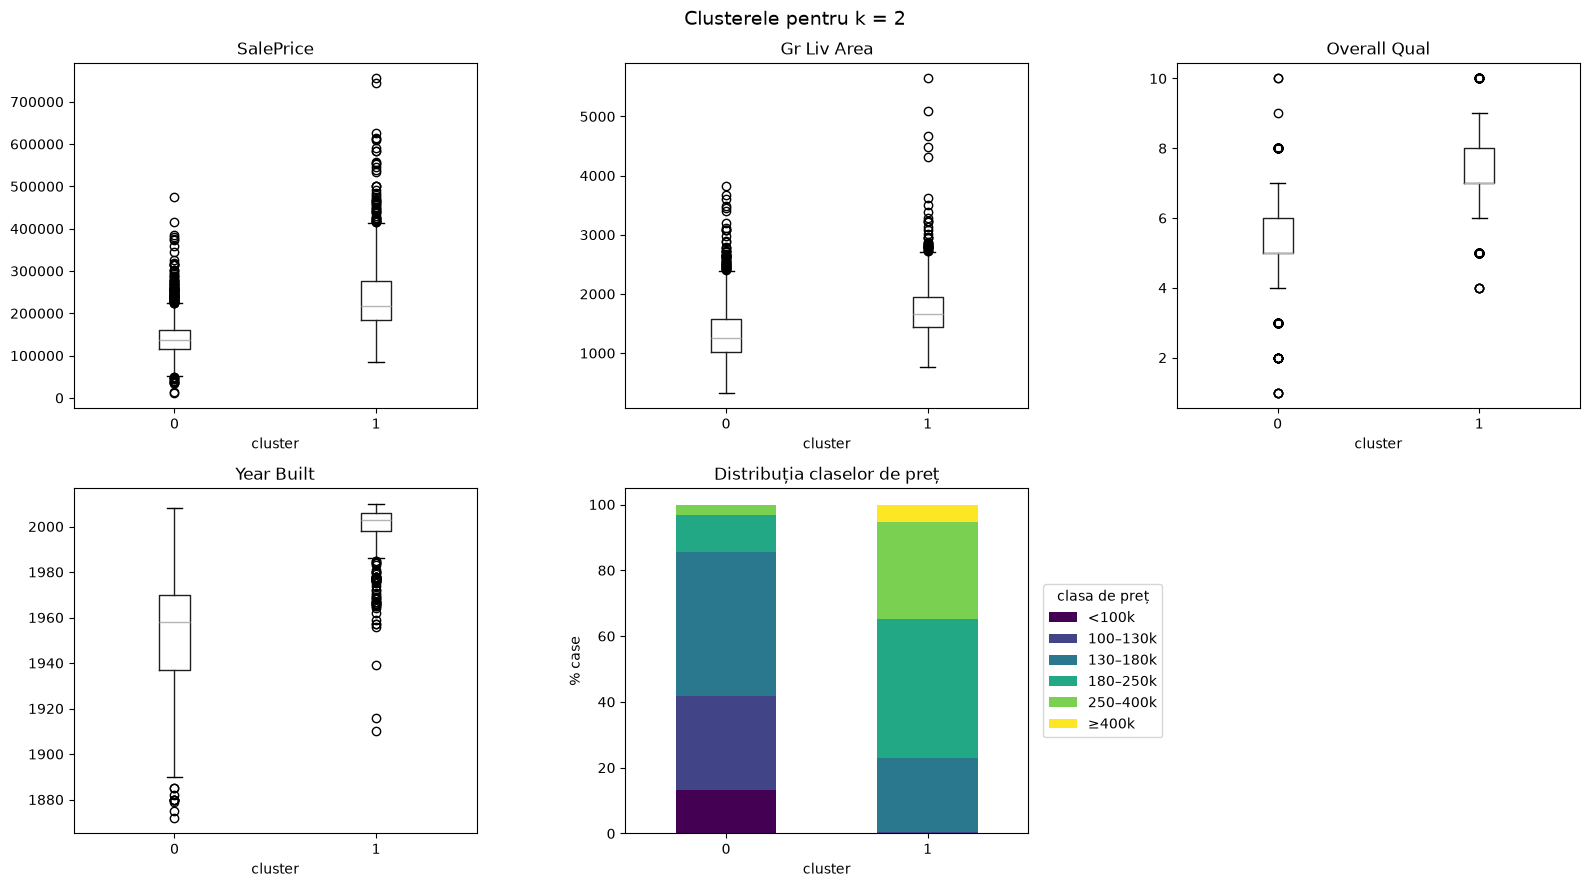

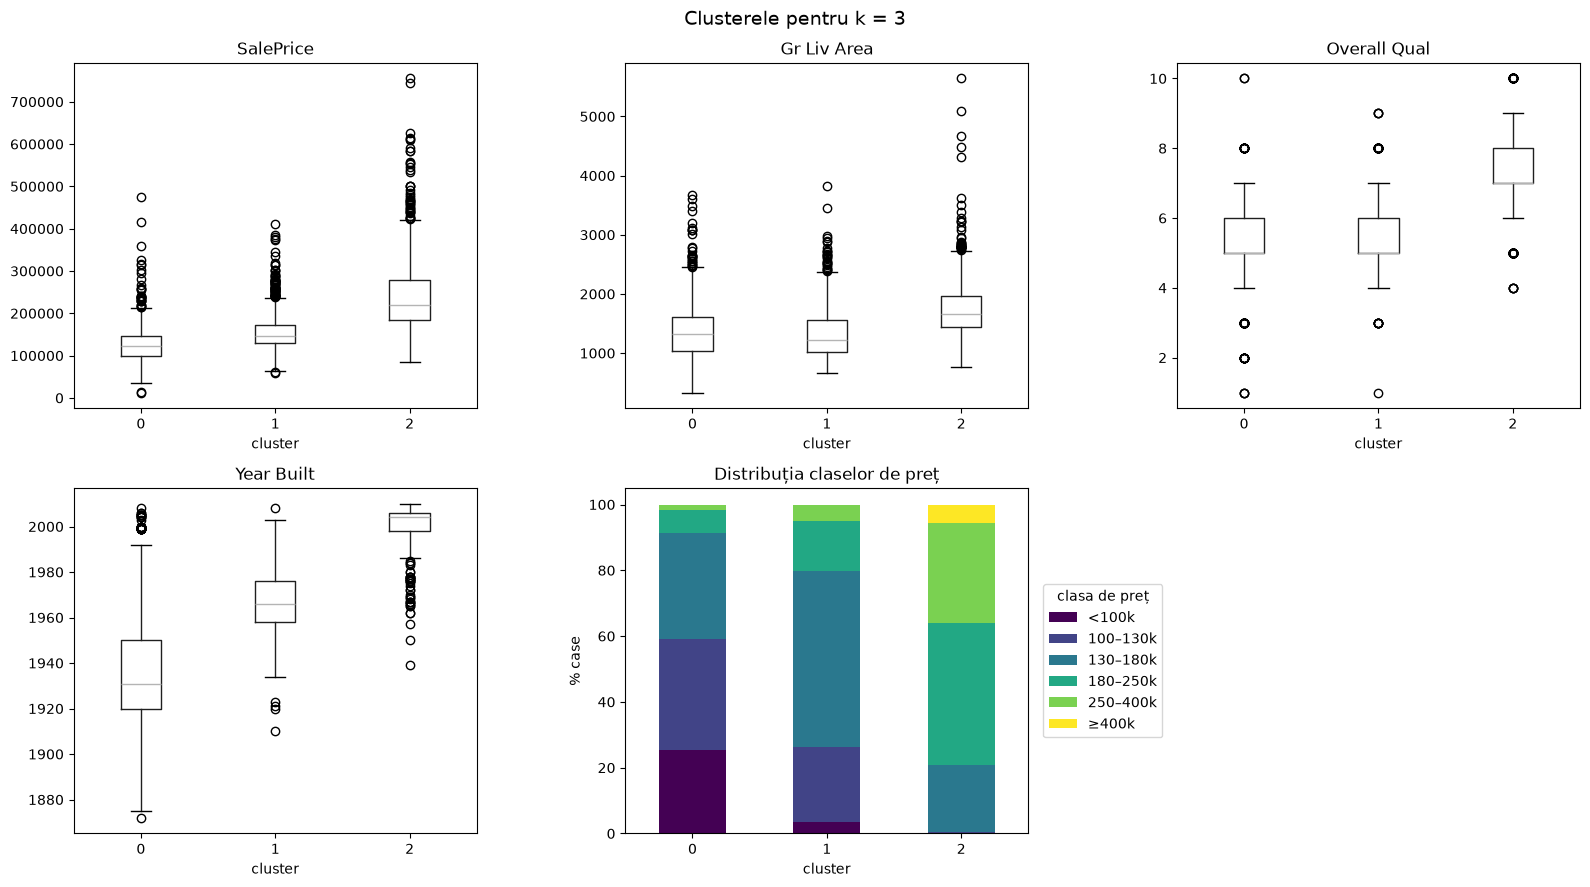

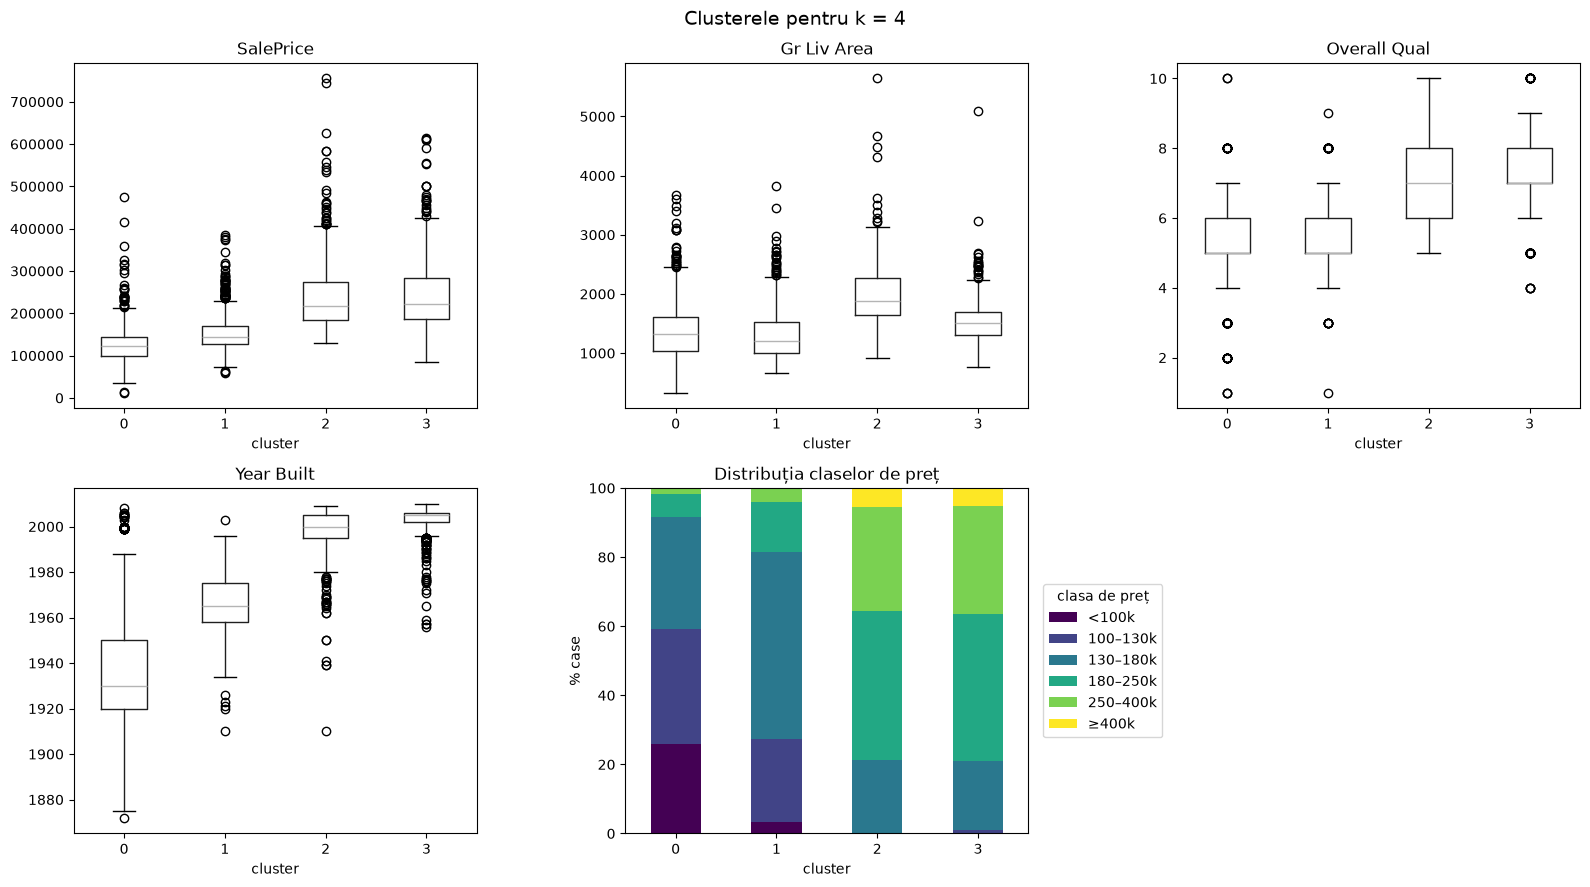

In [30]:
def grafice_cluster(k):
    d = raw.assign(cluster=labels[k], PriceClass=y.to_numpy())
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, col in zip(axes.flat[:4], ["SalePrice", "Gr Liv Area", "Overall Qual", "Year Built"]):
        d.boxplot(column=col, by="cluster", ax=ax, grid=False)
        ax.set_title(col); ax.set_xlabel("cluster")
    ct = pd.crosstab(d["cluster"], d["PriceClass"], normalize="index") * 100
    ct = ct.reindex(columns=range(6), fill_value=0)
    ct.columns = CLASS_NAMES
    ct.plot(kind="bar", stacked=True, ax=axes[1, 1], colormap="viridis", rot=0)
    axes[1, 1].set(title="Distribuția claselor de preț", xlabel="cluster", ylabel="% case")
    axes[1, 1].legend(title="clasa de preț", loc="center left", bbox_to_anchor=(1.02, 0.5))
    axes[1, 2].axis("off")
    fig.suptitle(f"Clusterele pentru k = {k}", fontsize=14)
    plt.tight_layout(); plt.show()

for k in [2, 3, 4]:
    grafice_cluster(k)

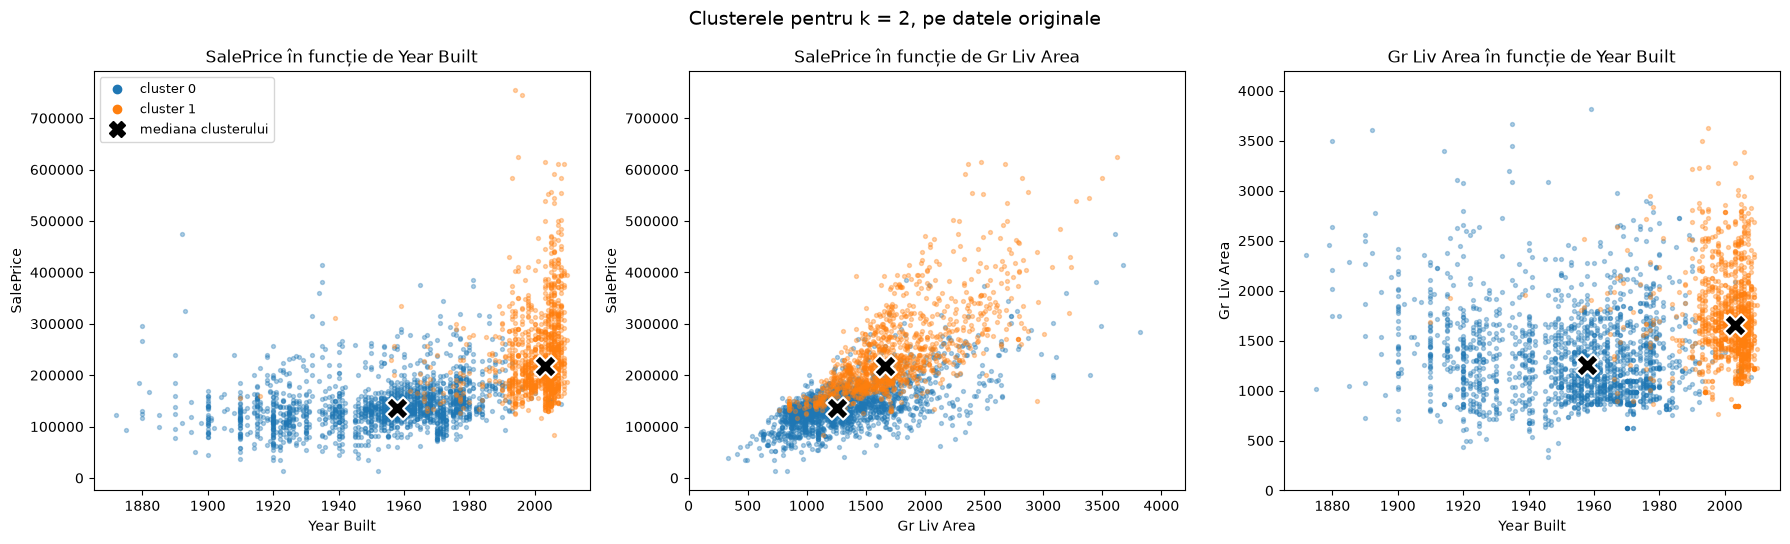

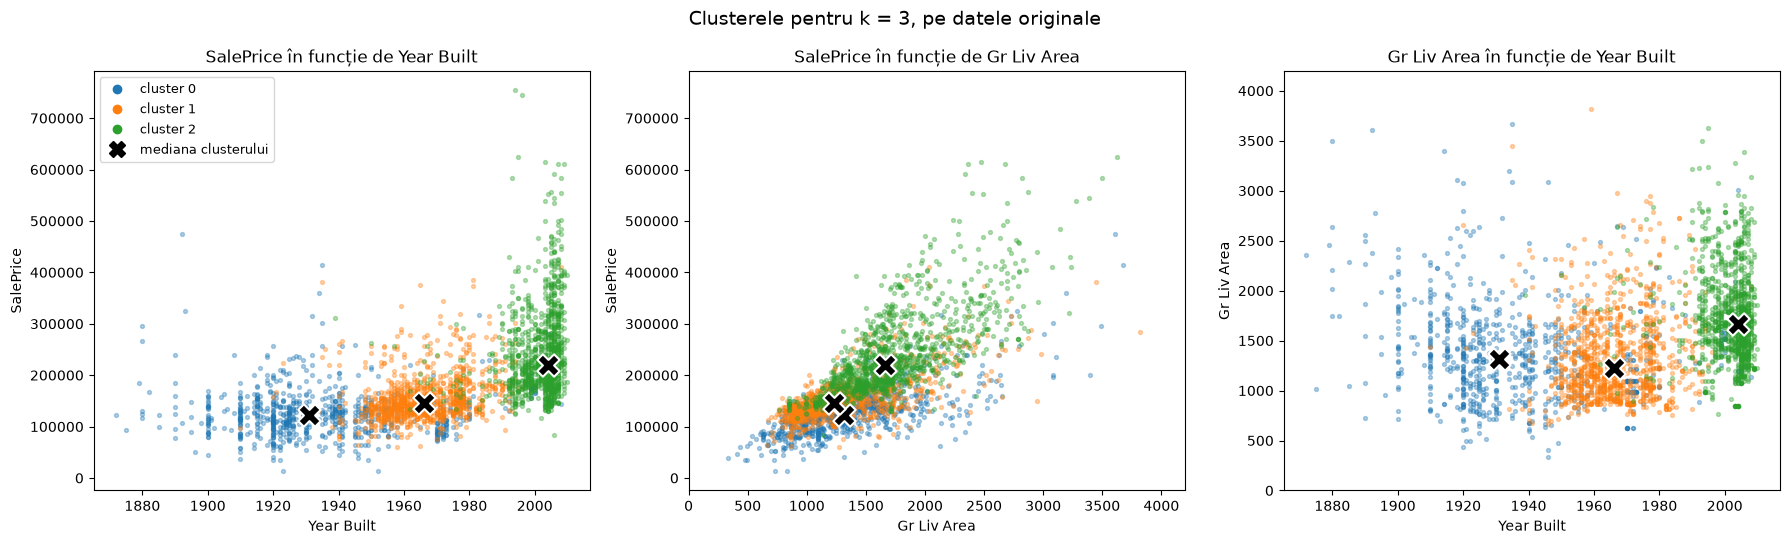

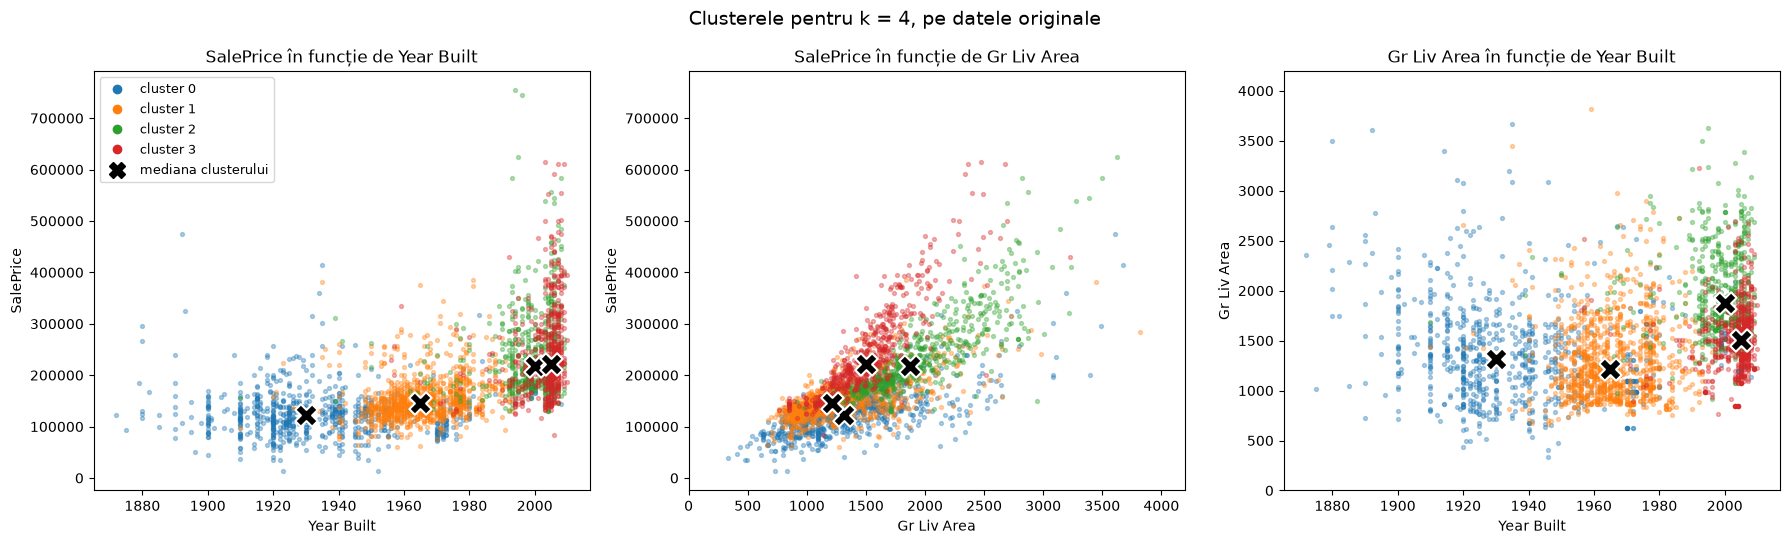

In [45]:
from matplotlib.lines import Line2D
TAB10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

def scatter_clustere(k):
    d = raw.assign(cluster=labels[k])
    perechi = [("Year Built", "SalePrice"), ("Gr Liv Area", "SalePrice"), ("Year Built", "Gr Liv Area")]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    for ax, (cx, cy) in zip(axes, perechi):
        for c in range(k):
            m = d["cluster"] == c
            ax.scatter(d.loc[m, cx], d.loc[m, cy], s=8, alpha=0.35, color=TAB10[c])
        med = d.groupby("cluster")[[cx, cy]].median()          # "centrul" fiecărui cluster, în unități originale
        ax.scatter(med[cx], med[cy], marker="X", s=260, c="black", edgecolors="white", linewidths=1.5, zorder=5)
        ax.set(xlabel=cx, ylabel=cy, title=f"{cy} în funcție de {cx}")
    axes[1].set_xlim(0, 4200); axes[2].set_ylim(0, 4200)       # ascunde 5 case cu Gr Liv Area > 4200, ca să se vadă restul
    h = [Line2D([], [], marker="o", ls="", color=TAB10[c], label=f"cluster {c}") for c in range(k)]
    h.append(Line2D([], [], marker="X", ls="", color="black", markersize=11, label="mediana clusterului"))
    axes[0].legend(handles=h, fontsize=9, loc="upper left")
    fig.suptitle(f"Clusterele pentru k = {k}, pe datele originale", fontsize=14)
    plt.tight_layout(); plt.show()

for k in [2, 3, 4]:
    scatter_clustere(k)

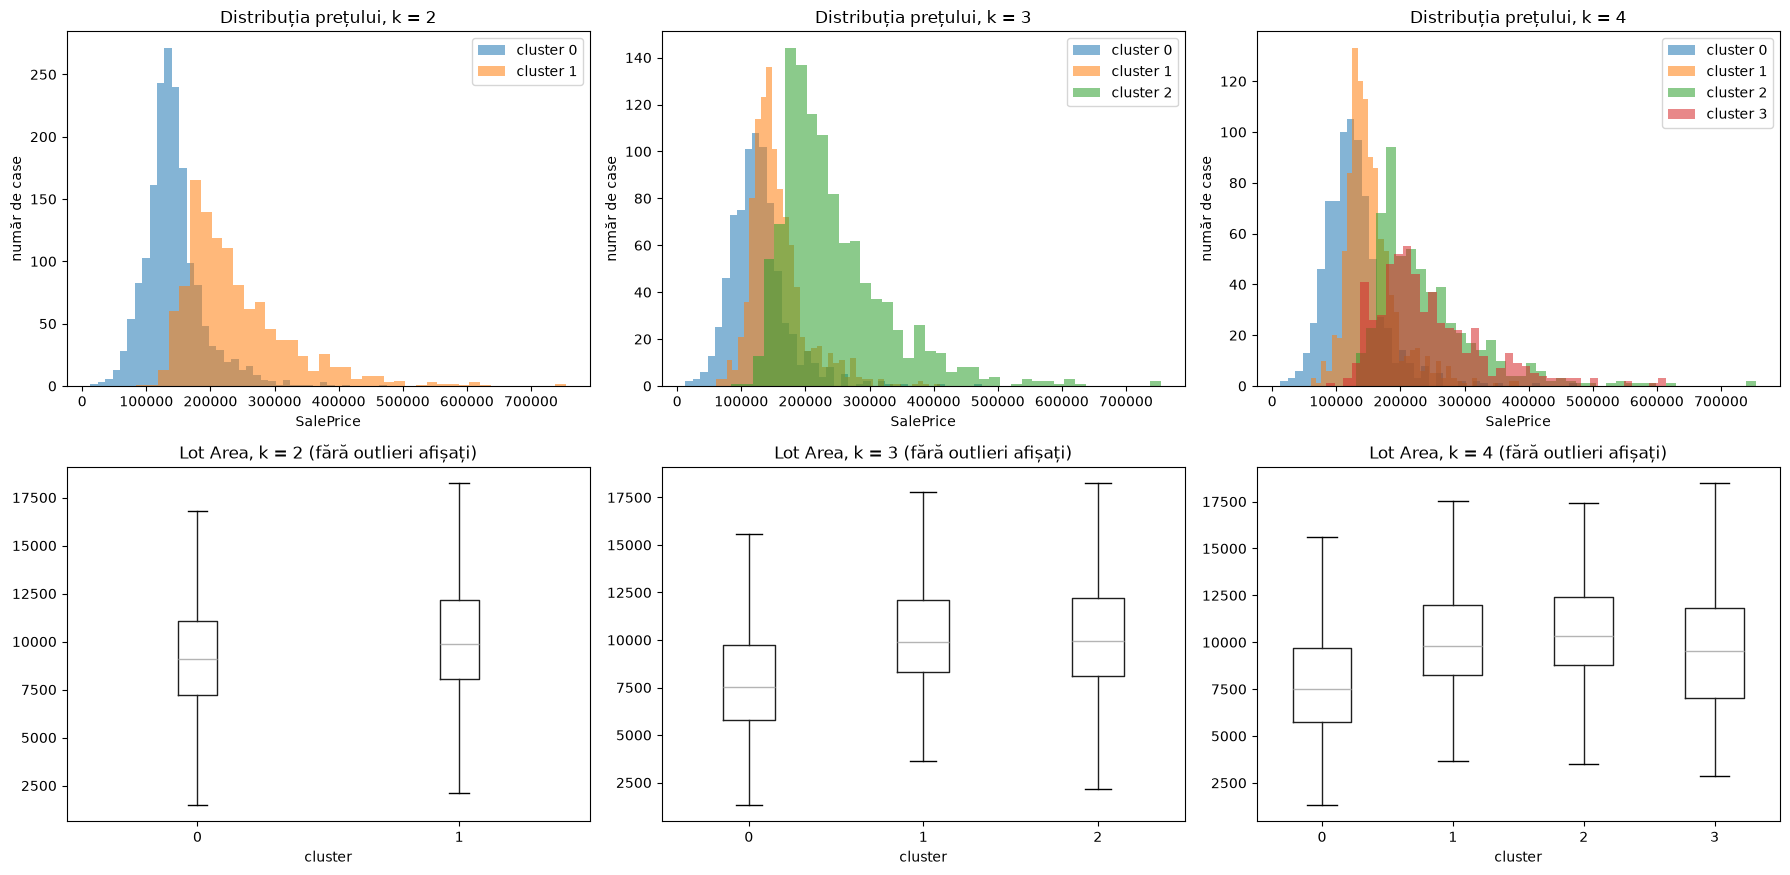

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for col, k in enumerate([2, 3, 4]):
    d = raw.assign(cluster=labels[k])
    ax = axes[0, col]
    for c in range(k):
        ax.hist(d.loc[d["cluster"] == c, "SalePrice"], bins=40, alpha=0.55, label=f"cluster {c}")
    ax.set(title=f"Distribuția prețului, k = {k}", xlabel="SalePrice", ylabel="număr de case")
    ax.legend()
    d.boxplot(column="Lot Area", by="cluster", ax=axes[1, col], grid=False, showfliers=False)
    axes[1, col].set(title=f"Lot Area, k = {k} (fără outlieri afișați)", xlabel="cluster")
fig.suptitle("")
plt.tight_layout(); plt.show()

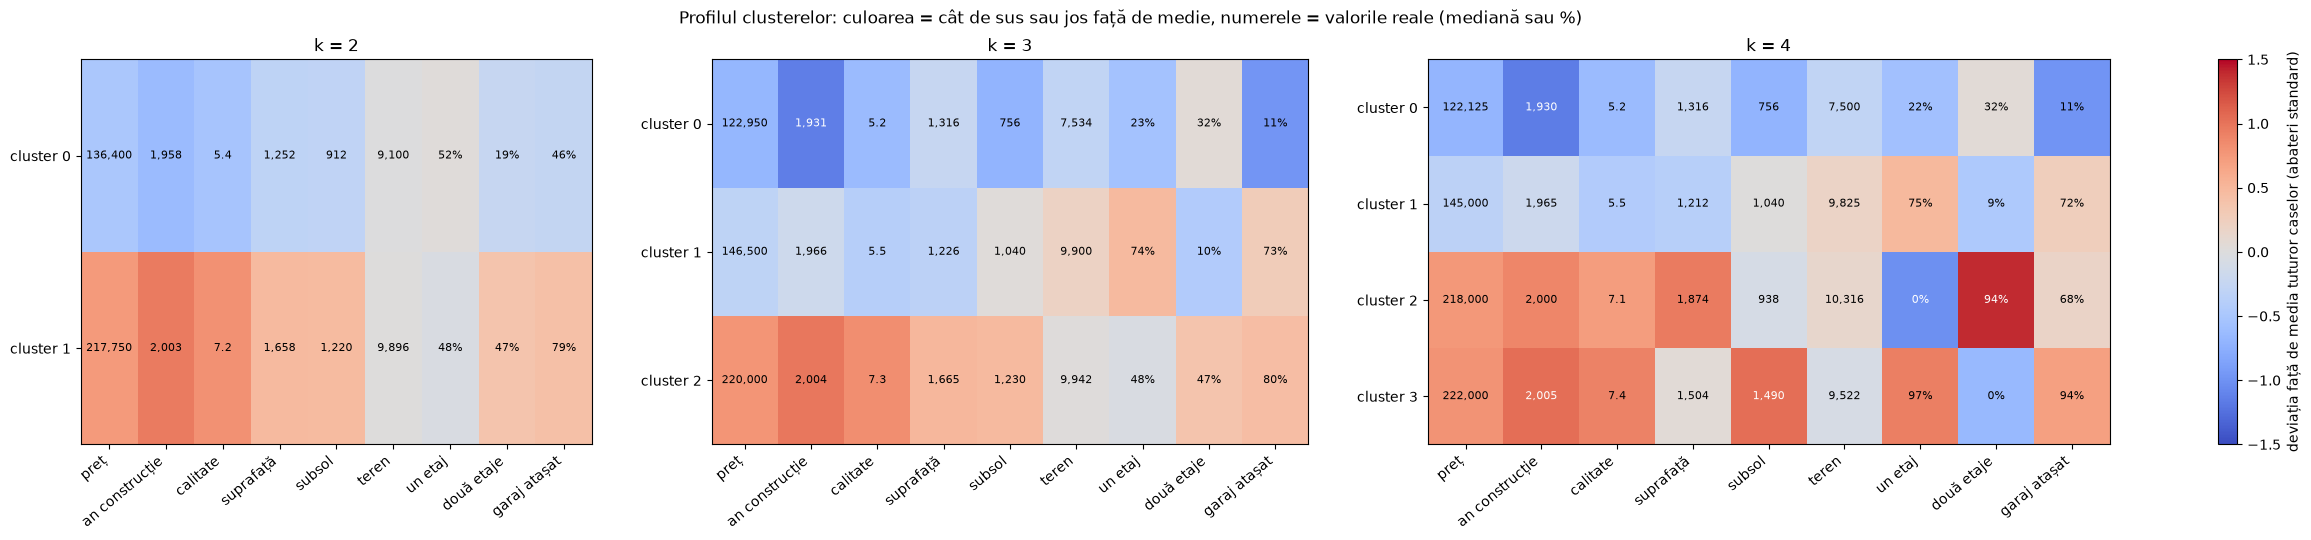

In [32]:
H_ = pd.DataFrame({
    "preț": raw["SalePrice"], "an construcție": raw["Year Built"], "calitate": raw["Overall Qual"],
    "suprafață": raw["Gr Liv Area"], "subsol": raw["Total Bsmt SF"], "teren": raw["Lot Area"],
    "un etaj": (raw["House Style"] == "1Story").astype(float),
    "două etaje": (raw["House Style"] == "2Story").astype(float),
    "garaj atașat": (raw["Garage Type"] == "Attchd").astype(float)})
procente = ["un etaj", "două etaje", "garaj atașat"]
ZS = (H_ - H_.mean()) / H_.std()                       # z-score față de toate casele

fig, axes = plt.subplots(1, 3, figsize=(28, 5), gridspec_kw={"width_ratios": [3, 3.5, 4]})
for ax, k in zip(axes, [2, 3, 4]):
    zc = ZS.groupby(labels[k]).mean()                  # culoarea
    real = H_.groupby(labels[k]).median()              # numerele afișate
    real["calitate"] = H_.groupby(labels[k])["calitate"].mean()
    for c in procente:
        real[c] = H_.groupby(labels[k])[c].mean() * 100
    im = ax.imshow(zc.values, cmap="coolwarm", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(zc.shape[1])); ax.set_xticklabels(zc.columns, rotation=40, ha="right")
    ax.set_yticks(range(k)); ax.set_yticklabels([f"cluster {c}" for c in range(k)])
    for i in range(k):
        for j, c in enumerate(zc.columns):
            v = real.iloc[i, j]
            text = f"{v:.0f}%" if c in procente else (f"{v:.1f}" if c == "calitate" else f"{v:,.0f}")
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if abs(zc.iloc[i, j]) > 1 else "black")
    ax.set_title(f"k = {k}")
fig.colorbar(im, ax=axes, label="deviația față de media tuturor caselor (abateri standard)", fraction=0.015)
fig.suptitle("Profilul clusterelor: culoarea = cât de sus sau jos față de medie, numerele = valorile reale (mediană sau %)")
plt.show()

**Interpretare**

**Histogramele prețului și `Lot Area` (graficele din Lab 1, acum pe clustere)**
- Histogramele prețului se suprapun mult: la k = 2 clusterele se întâlnesc în zona 150.000–250.000 . La k = 4, clusterele 2 și 3 au distribuții aproape identice (prețuri mediane 218.000 $ și 222.000 ), deci se deosebesc prin formă, nu prin preț.
- `Lot Area`: clusterul 0 (cele mai vechi) are terenul cel mai mic, cu mediana de 7500 sqft. Celelalte trei clustere au medianele 9825, 10316 și 9522,5 sqft.

**k = 2.**
- Cluster 0: case mai vechi (anul median ≈ 1958), calitate medie, suprafață și preț mai mici.
- Cluster 1: case noi (anul median ≈ 2003), calitate mare, mai mari și mai scumpe.

**k = 3.** Casele vechi se împart în două:
- Cluster 0: cele mai vechi (în jur de 1931), fără garaj atașat, cele mai ieftine.
- Cluster 1: case cu un etaj din anii 1960 mostly cu un etaj, cu garaj atașat.
- Cluster 2: casele noi.

**k = 4.** Casele noi se împart după formă:
- Cluster 2: case noi cu un etaj.
- Cluster 3: case noi cu două etaje.

**Concluzie:** clusterele urmează în primul rând vechimea (PC1) și apoi stilul casei (PC2). Nu se ia dupa pret.

## 3.2 Inferență: case inventate

Inventez 6 case plauzibile și văd în ce cluster le pune modelul. Pentru fiecare casă setez doar atributele principale (an, cartier, etaje, suprafețe, calitate, garaj, fundație, exterior). Restul features-urilor primesc valoarea tipică din setul de date (mediana pentru cele numerice, valoarea cea mai frecventă pentru cele categorice), ca să obțin o casă completă, nu una cu zeci de coloane one-hot egale cu 0.

- **A:** veche și mică (1925, OldTown, 1 etaj, 1000 sqft, calitate 4, garaj detașat)
- **B:** nouă, 2 etaje (2005, Gilbert, 1700 sqft, calitate 7, garaj atașat)
- **C:** nouă, 1 etaj, subsol mare (2006, NridgHt, 1500 sqft la parter și 1500 la subsol, calitate 7)
- **D:** din anii '60, 1 etaj (1965, NAmes, 1200 sqft, calitate 5, garaj atașat)
- **E:** de lux, 2 etaje (2008, NoRidge, 3300 sqft, calitate 10, 3 mașini în garaj)
- **F:** veche, dar renovată (1920, renovată în 2008, OldTown, 2 etaje, calitate 8)

Înainte de rulare am notat ce aștept din profilurile de la 3.1: A → cel mai vechi cluster, B → cluster nou cu 2 etaje, C → cluster nou cu 1 etaj, D → cluster din anii '60, E → cluster nou cu 2 etaje, F → neclar (vechime mare, dar calitate mare).

Înainte de inferență trec casele prin exact aceleași transformări ca datele de antrenare: codificare, scalare min-max (cu min și max-ul celor 2930 de case) și PCA.

## creez casele

In [33]:
from lab3_utils import fill_missing, encode_features, project

df_f = fill_missing(clean_data(load_data(PATH)))     # aceeași pregătire ca în get_data(impute=True)
est_cat = lambda c: df_f[c].dtype == object or str(df_f[c].dtype) == "str"
tipica = {c: (df_f[c].mode().iloc[0] if est_cat(c) else df_f[c].median()) for c in df_f.columns}

def casa(nume, **kw):
    r = dict(tipica); r.update(kw)
    r["Gr Liv Area"] = r["1st Flr SF"] + r["2nd Flr SF"] + r["Low Qual Fin SF"]
    r["Garage Yr Blt"] = r["Year Built"]
    r["Bsmt Unf SF"] = r["Total Bsmt SF"]; r["BsmtFin SF 1"] = 0; r["BsmtFin SF 2"] = 0
    r["Bsmt Full Bath"] = 0; r["Bsmt Half Bath"] = 0
    r["Order"] = 0; r["PID"] = 0; r["SalePrice"] = 0          # coloane ignorate la codificare
    r["_nume"] = nume
    return r

H = [
 casa("A: veche și mică", **{"MS SubClass":30,"Year Built":1925,"Year Remod/Add":1950,"Neighborhood":"OldTown","House Style":"1Story",
     "1st Flr SF":1000,"2nd Flr SF":0,"Low Qual Fin SF":0,"Total Bsmt SF":700,"Overall Qual":4,"Foundation":"CBlock","Exterior 1st":"Wd Sdng","Exterior 2nd":"Wd Sdng",
     "Garage Type":"Detchd","Garage Cars":1,"Garage Area":250,"Lot Area":6500,"Full Bath":1,"Bedroom AbvGr":2,"TotRms AbvGrd":5,"Fireplaces":0,"BsmtFin Type 1":"Unf"}),
 casa("B: nouă, 2 etaje", **{"MS SubClass":60,"Year Built":2005,"Year Remod/Add":2005,"Neighborhood":"Gilbert","House Style":"2Story",
     "1st Flr SF":900,"2nd Flr SF":800,"Low Qual Fin SF":0,"Total Bsmt SF":900,"Overall Qual":7,"Foundation":"PConc","Exterior 1st":"VinylSd","Exterior 2nd":"VinylSd",
     "Garage Type":"Attchd","Garage Cars":2,"Garage Area":500,"Lot Area":9500,"Full Bath":2,"Half Bath":1,"Bedroom AbvGr":3,"TotRms AbvGrd":7,"Fireplaces":1,"Kitchen Qual":"Gd","Exter Qual":"Gd","BsmtFin Type 1":"Unf"}),
 casa("C: nouă, 1 etaj, subsol mare", **{"MS SubClass":20,"Year Built":2006,"Year Remod/Add":2006,"Neighborhood":"NridgHt","House Style":"1Story",
     "1st Flr SF":1500,"2nd Flr SF":0,"Low Qual Fin SF":0,"Total Bsmt SF":1500,"Overall Qual":7,"Foundation":"PConc","Exterior 1st":"VinylSd","Exterior 2nd":"VinylSd",
     "Garage Type":"Attchd","Garage Cars":2,"Garage Area":550,"Lot Area":10000,"Full Bath":2,"Bedroom AbvGr":3,"TotRms AbvGrd":6,"Fireplaces":1,"Kitchen Qual":"Gd","Exter Qual":"Gd","BsmtFin Type 1":"Unf"}),
 casa("D: din anii '60, 1 etaj", **{"MS SubClass":20,"Year Built":1965,"Year Remod/Add":1965,"Neighborhood":"NAmes","House Style":"1Story",
     "1st Flr SF":1200,"2nd Flr SF":0,"Low Qual Fin SF":0,"Total Bsmt SF":1100,"Overall Qual":5,"Foundation":"CBlock","Exterior 1st":"Wd Sdng","Exterior 2nd":"Wd Sdng",
     "Garage Type":"Attchd","Garage Cars":1,"Garage Area":300,"Lot Area":9900,"Full Bath":1,"Bedroom AbvGr":3,"TotRms AbvGrd":6,"Fireplaces":0,"BsmtFin Type 1":"Unf"}),
 casa("E: de lux, 2 etaje", **{"MS SubClass":60,"Year Built":2008,"Year Remod/Add":2008,"Neighborhood":"NoRidge","House Style":"2Story",
     "1st Flr SF":1800,"2nd Flr SF":1500,"Low Qual Fin SF":0,"Total Bsmt SF":1800,"Overall Qual":10,"Foundation":"PConc","Exterior 1st":"VinylSd","Exterior 2nd":"VinylSd",
     "Garage Type":"Attchd","Garage Cars":3,"Garage Area":850,"Lot Area":15000,"Full Bath":3,"Half Bath":1,"Bedroom AbvGr":4,"TotRms AbvGrd":10,"Fireplaces":2,"Kitchen Qual":"Ex","Exter Qual":"Ex","BsmtFin Type 1":"Unf"}),
 casa("F: veche, renovată", **{"MS SubClass":60,"Year Built":1920,"Year Remod/Add":2008,"Neighborhood":"OldTown","House Style":"2Story",
     "1st Flr SF":900,"2nd Flr SF":700,"Low Qual Fin SF":0,"Total Bsmt SF":800,"Overall Qual":8,"Foundation":"BrkTil","Exterior 1st":"Wd Sdng","Exterior 2nd":"Wd Sdng",
     "Garage Type":"Detchd","Garage Cars":1,"Garage Area":300,"Lot Area":7000,"Full Bath":2,"Bedroom AbvGr":3,"TotRms AbvGrd":7,"Fireplaces":1,"Kitchen Qual":"Gd","Exter Qual":"Gd","BsmtFin Type 1":"Unf"}),
]
casele = pd.DataFrame(H).set_index("_nume")

def codifica(houses):
    """Aceeași codificare ca get_data: adaug casele la setul complet (ca get_dummies să dea aceleași coloane), apoi le iau înapoi."""
    n = len(houses)
    tot = pd.concat([df_f, houses.reset_index(drop=True)[df_f.columns]], ignore_index=True)
    E = encode_features(tot, ordinal=True)
    E = E.fillna(E.median())
    return E.iloc[-n:].reindex(columns=X.columns).set_index(houses.index)

Xn = codifica(casele)
print(Xn.shape, "| NaN:", Xn.isna().sum().sum())

# verificare: case REALE prin același traseu trebuie să dea exact Z
real = df_f.iloc[:5].copy(); real.index = [f"real{i}" for i in range(5)]
Xr = codifica(real)
print("X identic:", np.allclose(Xr.values, X.iloc[:5].values), "| Z identic:", np.allclose(project(Xr, B), Z[:5]))

(6, 250) | NaN: 0
X identic: True | Z identic: True


c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


## le pun in clustere

In [34]:
Zn = project(Xn, B)          # scalare min-max (cu min/max din cele 2930 de case), apoi PCA-ul antrenat

asteptat = {"A: veche și mică": 0, "B: nouă, 2 etaje": 2, "C: nouă, 1 etaj, subsol mare": 3,
            "D: din anii '60, 1 etaj": 1, "E: de lux, 2 etaje": 2, "F: veche, renovată": "neclar"}   # scris înainte de rulare (k = 4)

rows = []
for k in [2, 3, 4]:
    km, rm = models[k]["km"], models[k]["remap"]
    ordine = sorted(rm, key=rm.get)                   # coloane în ordinea clusterelor renumerotate
    D = km.transform(Zn)[:, ordine]                   # distanța fiecărei case la fiecare centroid
    for i, nume in enumerate(casele.index):
        s = np.argsort(D[i])
        rows.append({"k": k, "casa": nume, "cluster": s[0], "dist. cluster": round(D[i, s[0]], 2),
                     "al 2-lea cluster": s[1], "dist. al 2-lea": round(D[i, s[1]], 2)})
rez = pd.DataFrame(rows)
display(rez)

k4 = rez[rez.k == 4].set_index("casa").drop(columns="k")
k4.insert(0, "așteptat (din 3.1)", pd.Series(asteptat))
display(k4)

# cât de departe sunt casele REALE de centroidul lor (ca să știm dacă 2-3 e mult sau puțin)
for k in [2, 3, 4]:
    d = models[k]["km"].transform(Z).min(axis=1)
    print(f"k = {k}: casele reale, distanța la centroid: mediană {np.median(d):.2f}, percentila 90: {np.percentile(d, 90):.2f}")

c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,k,casa,cluster,dist. cluster,al 2-lea cluster,dist. al 2-lea
0,2,A: veche și mică,0,2.39,1,3.67
1,2,"B: nouă, 2 etaje",1,2.04,0,2.98
2,2,"C: nouă, 1 etaj, subsol mare",1,2.09,0,2.75
3,2,"D: din anii '60, 1 etaj",0,2.15,1,3.22
4,2,"E: de lux, 2 etaje",1,2.27,0,3.28
5,2,"F: veche, renovată",0,2.77,1,3.37
6,3,A: veche și mică,0,2.44,1,2.73
7,3,"B: nouă, 2 etaje",2,2.02,1,3.13
8,3,"C: nouă, 1 etaj, subsol mare",2,2.08,1,2.70
9,3,"D: din anii '60, 1 etaj",1,2.02,0,2.80


,așteptat (din 3.1),cluster,dist. cluster,al 2-lea cluster,dist. al 2-lea
casa,,,,,
A: veche și mică,0,0,2.45,1,2.71
"B: nouă, 2 etaje",2,2,1.63,3,2.76
"C: nouă, 1 etaj, subsol mare",3,3,1.91,2,2.67
"D: din anii '60, 1 etaj",1,1,2.01,0,2.81
"E: de lux, 2 etaje",2,2,1.90,3,2.93
"F: veche, renovată",neclar,0,2.52,2,3.16


k = 2: casele reale, distanța la centroid: mediană 2.97, percentila 90: 3.64
k = 3: casele reale, distanța la centroid: mediană 2.85, percentila 90: 3.52
k = 4: casele reale, distanța la centroid: mediană 2.80, percentila 90: 3.50


## le arat pe grafic 

k = 2: centroid cel mai apropiat doar în PC1–PC2 = [np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0)] | atribuit în 123 dim = [0, 1, 1, 0, 1, 0]
k = 3: centroid cel mai apropiat doar în PC1–PC2 = [np.int64(0), np.int64(2), np.int64(2), np.int64(1), np.int64(2), np.int64(0)] | atribuit în 123 dim = [0, 2, 2, 1, 2, 0]
k = 4: centroid cel mai apropiat doar în PC1–PC2 = [np.int64(0), np.int64(2), np.int64(3), np.int64(1), np.int64(2), np.int64(0)] | atribuit în 123 dim = [0, 2, 3, 1, 2, 0]


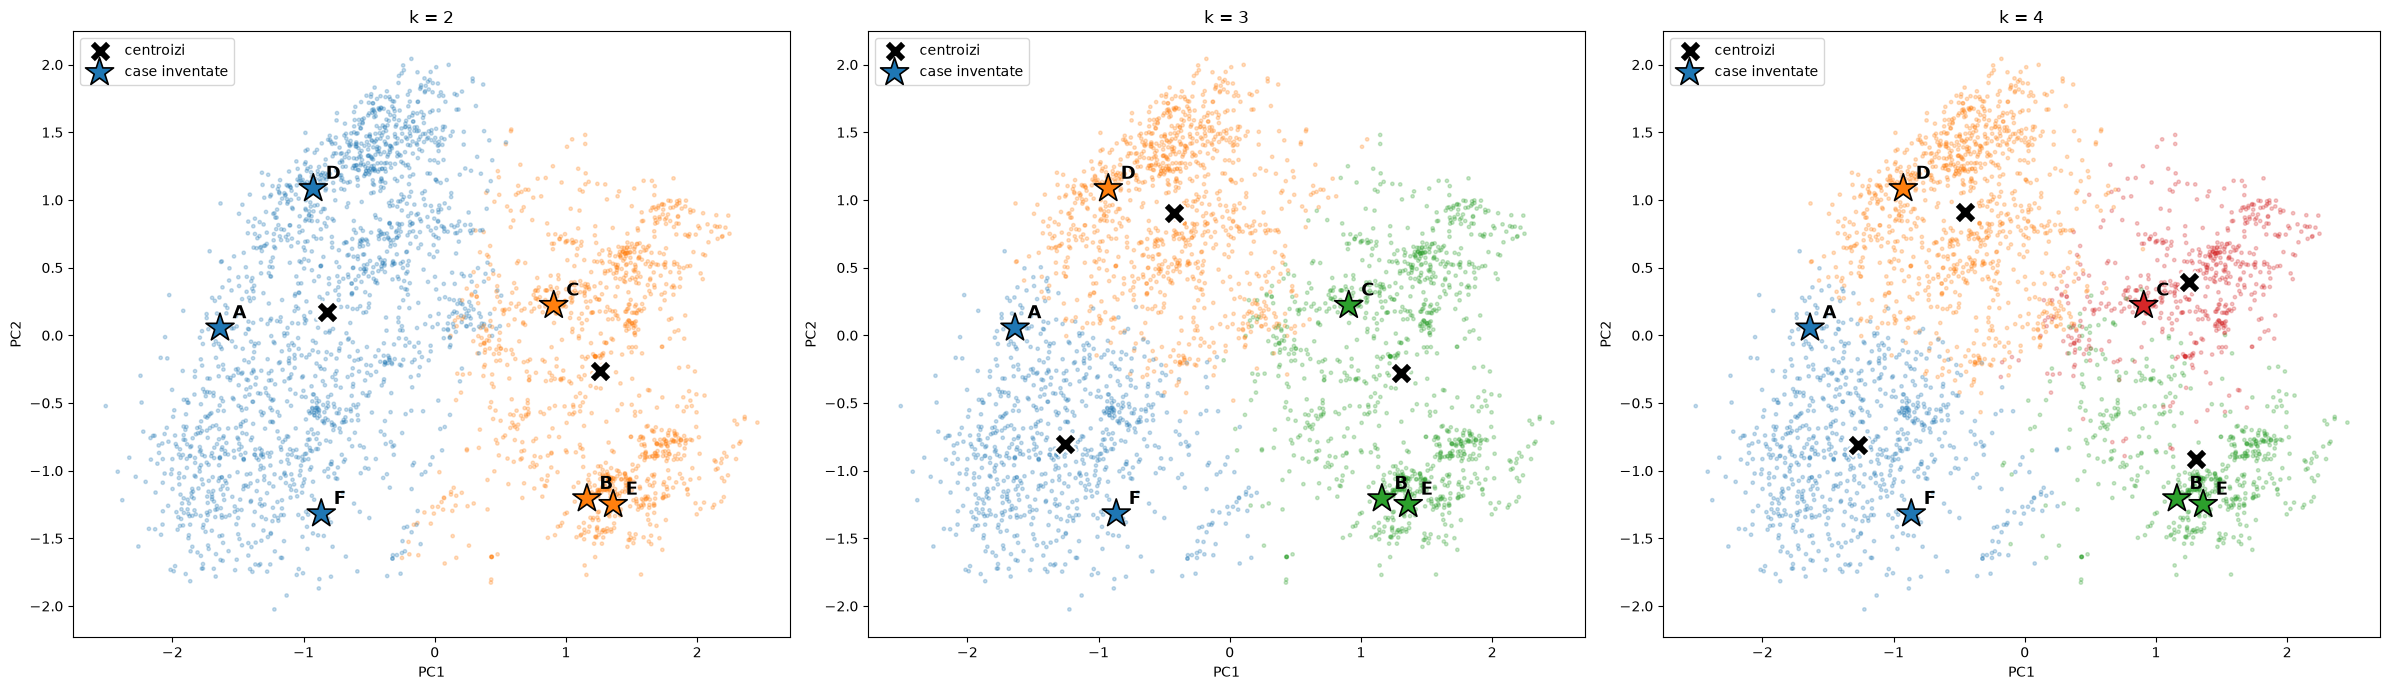

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, k in zip(axes, [2, 3, 4]):
    km, rm = models[k]["km"], models[k]["remap"]
    ordine = sorted(rm, key=rm.get)
    cent = km.cluster_centers_[ordine]                      # centroizii în ordinea clusterelor renumerotate
    lab = [rm[l] for l in km.predict(Zn)]

    ax.scatter(Z[:, 0], Z[:, 1], c=labels[k], cmap="tab10", vmin=0, vmax=9, s=6, alpha=0.25)
    ax.scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=260, edgecolors="white",
               linewidths=1.5, label="centroizi")
    ax.scatter(Zn[:, 0], Zn[:, 1], c=lab, cmap="tab10", vmin=0, vmax=9, marker="*", s=450,
               edgecolors="black", linewidths=1.2, label="case inventate")
    for (x, yy), nume in zip(Zn[:, :2], casele.index):
        ax.annotate(nume[0], (x, yy), textcoords="offset points", xytext=(9, 7), fontsize=13, fontweight="bold")
    ax.set(title=f"k = {k}", xlabel="PC1", ylabel="PC2"); ax.legend(loc="upper left")

    # verificare: planul 2D arată doar 2 din 123 de dimensiuni; atribuirea reală se face în toate 123
    d2 = np.argmin(((Zn[:, None, :2] - cent[None, :, :2]) ** 2).sum(-1), axis=1)
    print(f"k = {k}: centroid cel mai apropiat doar în PC1–PC2 = {list(d2)} | atribuit în 123 dim = {lab}")
plt.tight_layout(); plt.show()

**Interpretare**

**Casele A, B, C și D** ajung exact în clusterele așteptate (k = 4: A → 0, B → 2, C → 3, D → 1). Ele se încadrează în profilurile de la 3.1:
- B (2 etaje) și C (1 etaj) sunt ambele „noi", deci la k = 2 și k = 3 cad în același cluster. Abia la k = 4 se separă după numărul de etaje, ca în partea 2.
- Distanța la centroid e mică (1,63 pentru B, față de 2,76 la al doilea cluster), deci atribuirea e clară.
- Casa A (veche și mică) are cea mai mică marjă la k = 3 și k = 4 (2,44 vs 2,73 și 2,45 vs 2,71). La k = 2 e clară (2,39 vs 3,67).

**Casa E (de lux)** ajunge în clusterul 2, cu B. Pentru „nouă, cu două etaje" e corect, dar casa E (calitate 10, 3300 sqft) și casa B (calitate 7, 1700 sqft) sunt puse în același grup. Niciun cluster nu reprezintă „case de lux": clusterul 2 are prețul median 218.000 $ și doar 6% din casele lui sunt în clasa ≥ 400k. Asta confirmă că nici k = 4 nu regăsește clasele de preț.

**Casa F (veche, renovată)** ajunge în clusterul 0, cel mai vechi și mai ieftin (preț median 122.125 $). Intuitiv, o casă cu calitate 8, renovată în 2008, nu ar trebui să fie acolo. Motivul se vede în loadings: pentru PC1, `Overall Qual` are doar 0,11, `Year Remod/Add` 0,25, în timp ce `Foundation_PConc` are 0,39 și `Garage Type_Detchd` −0,26. Casa F are fundație BrkTil, garaj detașat și exterior Wd Sdng, deci PC1 o vede ca veche. Dacă schimb pe rând doar fundația, doar garajul sau doar anul garajului, rămâne în clusterul 0. Abia când schimb simultan fundația (PConc), garajul (atașat) și exteriorul (VinylSd), trece în clusterul 2.

In [36]:
def cluster_k4(ch):
    Zc = project(codifica(ch), B)
    return [models[4]["remap"][l] for l in models[4]["km"].predict(Zc)][0]

F = casele.loc[["F: veche, renovată"]]
def schimba(**kw):
    t = F.copy()
    for c, v in kw.items():
        t[c] = v
    return t

variante = {
    "F original": schimba(),
    "F + fundație PConc": schimba(Foundation="PConc"),
    "F + garaj atașat": schimba(**{"Garage Type": "Attchd"}),
    "F + garaj construit în 2008": schimba(**{"Garage Yr Blt": 2008}),
    "F + PConc + garaj atașat + VinylSd": schimba(Foundation="PConc", **{"Garage Type": "Attchd", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd"}),
}
for nume, ch in variante.items():
    print(f"{nume:40s} -> cluster {cluster_k4(ch)}")

c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


F original                               -> cluster 0
F + fundație PConc                       -> cluster 0
F + garaj atașat                         -> cluster 0
F + garaj construit în 2008              -> cluster 0
F + PConc + garaj atașat + VinylSd       -> cluster 2


c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\stefa\OneDrive\Desktop\ML-lab\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [37]:
# 1) fără PCA: dimensiunile nu se potrivesc
try:
    models[4]["km"].predict(Xn.values)
except ValueError as e:
    print("EROARE:", e)

# 2) PCA, dar fără scalarea min-max: ce se întâmplă cu casele REALE?
Zfs = B["pca"].transform(X)
for k in [2, 3, 4]:
    lb = np.array([models[k]["remap"][l] for l in models[k]["km"].predict(Zfs)])
    print(f"k = {k}: fără scalare, case pe cluster = {np.bincount(lb, minlength=k)} (corect: {np.bincount(labels[k])})")

EROARE: X has 250 features, but KMeans is expecting 123 features as input.
k = 2: fără scalare, case pe cluster = [   0 2930] (corect: [1774 1156])
k = 3: fără scalare, case pe cluster = [   0    0 2930] (corect: [ 790 1041 1099])
k = 4: fără scalare, case pe cluster = [   0    0  726 2204] (corect: [ 774 1023  571  562])


**De ce trebuie transformat punctul cu PCA înainte de inferență?**

1. **Centroizii sunt definiți în spațiul PCA.** K-means a fost antrenat pe cele 123 de coordonate `Z`, nu pe cele 250 de features. O casă nouă cu 250 de valori nici nu poate fi comparată cu centroizii: modelul dă eroare (`250 features, but KMeans is expecting 123`).
2. **Trebuie aceeași transformare ca la antrenare, în aceeași ordine:** mai întâi scalarea min-max cu min și max-ul celor 2930 de case, apoi PCA-ul deja antrenat. Am verificat că traseul reproduce exact `Z` pentru case reale.
3. **Fără scalarea min-max, rezultatul nu are sens.** Am măsurat: toate cele 2930 de case ajung într-un singur cluster la k = 2 și k = 3, și în doar două la k = 4. Componentele PCA și centroizii există doar pentru valori scalate în [0, 1], iar valori brute (de exemplu `Year Built` ≈ 2000) le proiectează departe de toți centroizii.
4. **Scalerul nu se potrivește din nou pe casele noi.** Dacă ar fi potrivit pe cele 6 case, fiecare feature ar avea min/max-ul din ele, iar scala ar fi complet diferită de cea de la antrenare. De aceea se folosește scalerul deja antrenat.

## 3.3 Bonus a: grafice 3D interactive

Desenez primele 3 componente principale pentru k = 2, 3 și 4, cu casele colorate după cluster și centroizii ca romburi negre. Graficele se pot roti și mări, iar la hover apar cartierul, stilul, anul, suprafața și prețul casei. Culorile sunt aceleași ca în graficele 2D de mai sus.

Primele 3 componente explică împreună doar 27% din varianță, deci graficul arată o parte din date. 

In [38]:
import plotly.graph_objects as go

TAB10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
evr = B["pca"].explained_variance_ratio_
hover = (raw["Neighborhood"] + " | " + raw["House Style"] + " | built " + raw["Year Built"].astype(str) + " | "
         + raw["Gr Liv Area"].astype(str) + " sqft | $" + raw["SalePrice"].map("{:,.0f}".format)).to_numpy()

def scatter3d_clustere(k):
    km, rm = models[k]["km"], models[k]["remap"]
    cent = km.cluster_centers_[sorted(rm, key=rm.get)]            # centroizii în ordinea clusterelor renumerotate
    fig = go.Figure()
    for c in range(k):
        m = labels[k] == c
        fig.add_trace(go.Scatter3d(x=Z[m, 0], y=Z[m, 1], z=Z[m, 2], mode="markers", name=f"cluster {c} ({m.sum()} case)",
                                   marker=dict(size=2.5, color=TAB10[c], opacity=0.6), text=hover[m], hoverinfo="text"))
    fig.add_trace(go.Scatter3d(x=cent[:, 0], y=cent[:, 1], z=cent[:, 2], mode="markers", name="centroizi",
                               marker=dict(size=9, symbol="diamond", color="black", line=dict(color="white", width=2)),
                               text=[f"centroid cluster {c}" for c in range(k)], hoverinfo="text"))
    fig.update_layout(title=f"k-means, k = {k}: primele 3 componente principale", height=700,
                      scene=dict(xaxis_title=f"PC1 ({evr[0]:.1%})", yaxis_title=f"PC2 ({evr[1]:.1%})",
                                 zaxis_title=f"PC3 ({evr[2]:.1%})"),
                      legend=dict(itemsizing="constant"))
    return fig

figuri_3d = {k: scatter3d_clustere(k) for k in [2, 3, 4]}
for k in [2, 3, 4]:
    figuri_3d[k].show()

In [39]:
print(f"Varianța explicată de PC1, PC2, PC3: {evr[:3].round(3)} | împreună: {evr[:3].sum():.1%}")

print("\nCorelația componentelor cu mărimi din date:")
corr = pd.DataFrame({c: [np.corrcoef(Z[:, i], v)[0, 1] for i in range(3)]
                     for c, v in {"PriceClass": y.to_numpy(), "Year Built": raw["Year Built"],
                                  "Overall Qual": raw["Overall Qual"], "Gr Liv Area": raw["Gr Liv Area"]}.items()},
                    index=["PC1", "PC2", "PC3"]).round(2)
display(corr)

def eta2(v, l):   # ce parte din varianța unei componente este explicată de apartenența la cluster (0 = deloc, 1 = tot)
    return sum((l == c).sum() * (v[l == c].mean() - v.mean()) ** 2 for c in np.unique(l)) / ((v - v.mean()) ** 2).sum()
print("\nCât din varianța fiecărei componente este explicată de clustere:")
display(pd.DataFrame({f"k = {k}": [eta2(Z[:, i], labels[k]) for i in range(3)] for k in [2, 3, 4]},
                     index=["PC1", "PC2", "PC3"]).round(2))

print("\nCentroizii în primele 3 componente (k = 4):")
km4, rm4 = models[4]["km"], models[4]["remap"]
display(pd.DataFrame(km4.cluster_centers_[sorted(rm4, key=rm4.get)][:, :3], columns=["PC1", "PC2", "PC3"]).round(2))

print("\nForma clusterelor (k = 4):")
rows = []
for c in range(4):
    m = labels[4] == c
    cen = km4.cluster_centers_[sorted(rm4, key=rm4.get)][c]
    sd = np.sqrt(np.sort(np.linalg.eigvalsh(np.cov(Z[m, :3].T)))[::-1])
    rows.append({"cluster": c, "case": m.sum(),
                 "dist. medie la centroid (123 dim)": np.sqrt(((Z[m] - cen) ** 2).sum(1)).mean().round(2),
                 "abateri std pe axa lungă / scurtă (PC1-3)": f"{sd[0]:.2f} / {sd[2]:.2f}"})
display(pd.DataFrame(rows))

# cât de bine reprezintă PC1–PC3 clusterele: k-means rulat doar pe 3 componente față de cel pe 123
from sklearn.metrics import adjusted_rand_score
for k in [2, 3, 4]:
    k3 = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z[:, :3])
    print(f"k = {k}: ARI (k-means pe PC1–PC3 vs pe toate componentele) = {adjusted_rand_score(labels[k], k3):.3f}")

Varianța explicată de PC1, PC2, PC3: [0.132 0.085 0.053] | împreună: 27.0%

Corelația componentelor cu mărimi din date:


,PriceClass,Year Built,Overall Qual,Gr Liv Area
PC1,0.75,0.85,0.71,0.45
PC2,0.04,0.13,-0.06,-0.26
PC3,-0.11,-0.02,-0.03,-0.29



Cât din varianța fiecărei componente este explicată de clustere:


,k = 2,k = 3,k = 4
PC1,0.75,0.82,0.82
PC2,0.05,0.56,0.74
PC3,0.03,0.10,0.40



Centroizii în primele 3 componente (k = 4):


,PC1,PC2,PC3
0,-1.27,-0.81,0.18
1,-0.46,0.91,-0.30
2,1.31,-0.92,-0.52
3,1.25,0.39,0.82



Forma clusterelor (k = 4):


,cluster,case,dist. medie la centroid (123 dim),abateri std pe axa lungă / scurtă (PC1-3)
0,0,774,3.21,0.66 / 0.42
1,1,1023,2.80,0.71 / 0.36
2,2,571,2.40,0.68 / 0.23
3,3,562,2.58,0.54 / 0.27


k = 2: ARI (k-means pe PC1–PC3 vs pe toate componentele) = 0.955
k = 3: ARI (k-means pe PC1–PC3 vs pe toate componentele) = 0.930
k = 4: ARI (k-means pe PC1–PC3 vs pe toate componentele) = 0.906


**Ce pattern-uri se văd în 3D**

- **PC1 e axa „cât de nouă și de bună e casa".** Are corelația 0,85 cu `Year Built`, 0,71 cu `Overall Qual` și 0,75 cu clasa de preț. Clusterele se așază în ordine pe această axă (centroizii k = 4 au PC1 = −1,27, −0,46, 1,31 și 1,25).
- **PC2 și PC3 nu au legătură cu prețul** (corelații 0,04 și −0,11 cu clasa de preț). Ele surprind stilul casei: la loadings, `House Style_1Story` e pozitiv și `House Style_2Story` negativ în ambele. Prețul variază deci doar pe orizontală, iar pe celelalte două axe casele cu prețuri diferite sunt amestecate.
- **PC3 contează doar la k = 4.** La k = 2 clusterele explică 3% din varianța lui PC3, la k = 4 explică 40%. Clusterele 2 (noi, 2 etaje) și 3 (noi, 1 etaj) se despart la fel de mult pe PC3 (−0,52 față de 0,82) cât pe PC2 (−0,92 față de 0,39).
- **Clusterele nu sunt egale și nu sunt sferice.** Distanța medie la centroid e 3,21 la clusterul 0 și 2,40 la clusterul 2. Clusterul 2 e turtit: abaterea standard pe PC3 e 0,23, față de 0,68 pe axa lui lungă.
- **Norul e continuu.** Clusterele se ating și se suprapun în 3D (și silhouette-ul din partea 2 era ≤ 0,13), deci k-means tăie un nor continuu în bucăți, nu regăsește grupuri separate.

**Atenție la interpretare:** cele 3 componente explică doar 27% din varianță, dar k-means pe 3 componente dă clusterele de pe 123 (ARI ≥ 0,91), deci graficul nu induce în eroare asupra clusterelor.

,k,metoda,ARI vs k-means,silhouette
0,2,k-means,1.000,0.103
1,2,Ward (ierarhic),0.722,0.091
2,2,GMM sferic,0.838,0.096
3,2,GMM diagonal,0.091,0.027
4,3,k-means,1.000,0.103
5,3,Ward (ierarhic),0.656,0.094
6,3,GMM sferic,0.838,0.094
7,3,GMM diagonal,0.064,-0.012
8,4,k-means,1.000,0.090
9,4,Ward (ierarhic),0.502,0.087


Distanța până la al 10-lea vecin (mediană): 2.54


,eps,clustere,zgomot,cel mai mare cluster,dimensiuni
0,2.0,15,1873,306,"[306, 263, 228, 54, 34]"
1,2.5,5,968,1894,"[1894, 38, 12, 10, 8]"
2,3.0,1,330,2600,[2600]
3,3.5,1,70,2860,[2860]
4,4.0,1,5,2925,[2925]


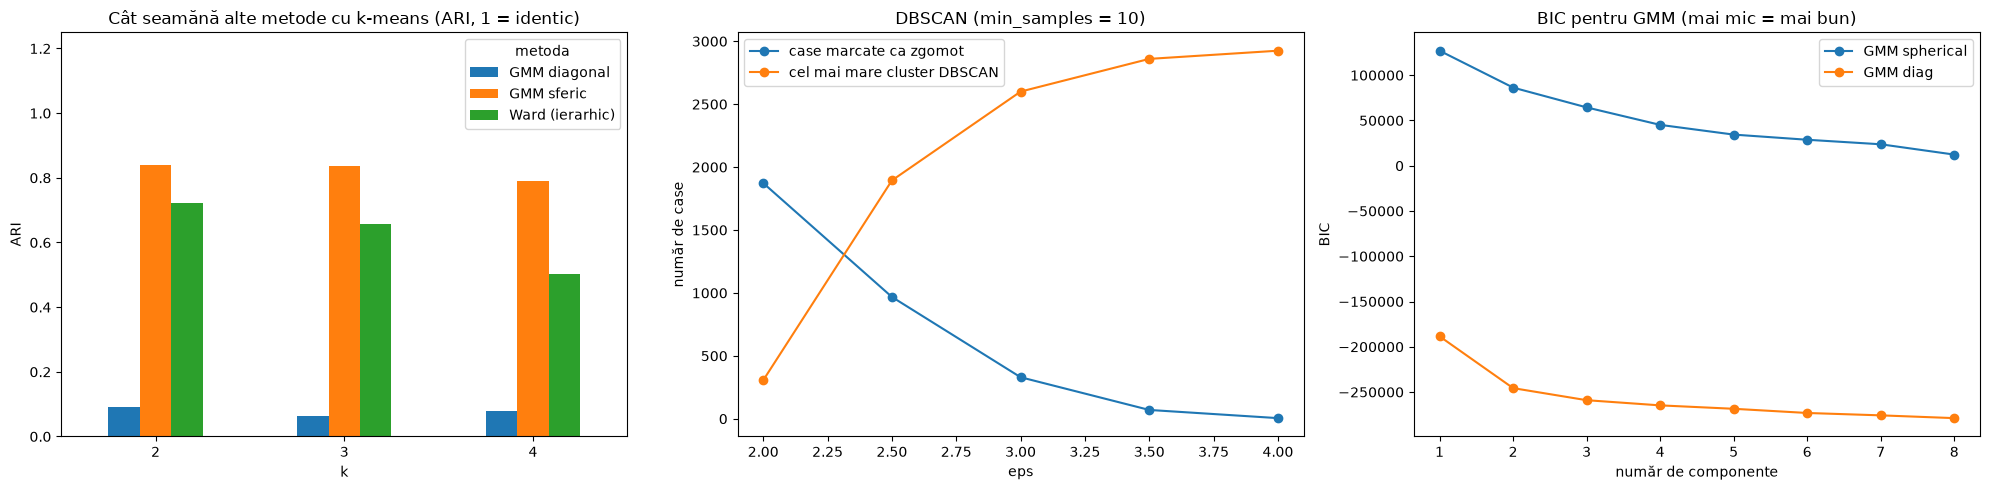

In [40]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# (a) alte metode cu același k: cât seamănă cu k-means (ARI) și cât de bine separă (silhouette)
rows = []
for k in [2, 3, 4]:
    alt = {"k-means": labels[k],
           "Ward (ierarhic)": AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z),
           "GMM sferic": GaussianMixture(n_components=k, covariance_type="spherical", n_init=5, random_state=42).fit_predict(Z),
           "GMM diagonal": GaussianMixture(n_components=k, covariance_type="diag", n_init=5, random_state=42).fit_predict(Z)}
    for nume, l in alt.items():
        rows.append({"k": k, "metoda": nume, "ARI vs k-means": adjusted_rand_score(labels[k], l),
                     "silhouette": silhouette_score(Z, l)})
comp = pd.DataFrame(rows)
display(comp.round(3))

# (b) DBSCAN: găsește grupuri separate prin zone de densitate mică?
d10 = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1]
print("Distanța până la al 10-lea vecin (mediană):", round(np.median(d10), 2))
rows = []
for eps in [2.0, 2.5, 3.0, 3.5, 4.0]:
    l = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
    dim = np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0])
    rows.append({"eps": eps, "clustere": len(dim) if (l >= 0).any() else 0, "zgomot": int((l == -1).sum()),
                 "cel mai mare cluster": int(dim.max()), "dimensiuni": sorted(dim.tolist(), reverse=True)[:5]})
dbs = pd.DataFrame(rows)
display(dbs)

# (c) BIC pentru GMM: indică vreun număr natural de grupuri?
n_list = range(1, 9)
bic = {cov: [GaussianMixture(n_components=n, covariance_type=cov, n_init=3, random_state=42).fit(Z).bic(Z) for n in n_list]
       for cov in ["spherical", "diag"]}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
comp[comp.metoda != "k-means"].pivot(index="k", columns="metoda", values="ARI vs k-means").plot(kind="bar", ax=axes[0], rot=0)
axes[0].set(title="Cât seamănă alte metode cu k-means (ARI, 1 = identic)", xlabel="k", ylabel="ARI", ylim=(0, 1.25))
axes[1].plot(dbs["eps"], dbs["zgomot"], "o-", label="case marcate ca zgomot")
axes[1].plot(dbs["eps"], dbs["cel mai mare cluster"], "o-", label="cel mai mare cluster DBSCAN")
axes[1].set(title="DBSCAN (min_samples = 10)", xlabel="eps", ylabel="număr de case"); axes[1].legend()
for cov, v in bic.items():
    axes[2].plot(list(n_list), v, "o-", label=f"GMM {cov}")
axes[2].set(title="BIC pentru GMM (mai mic = mai bun)", xlabel="număr de componente", ylabel="BIC"); axes[2].legend()
plt.tight_layout(); plt.show()

**Este k-means potrivit pentru aceste date?**

Am încercat trei alternative pe aceleași 123 de componente, ca să văd dacă o altă metodă găsește grupuri mai clare.

- **Ward (clustering ierarhic):** seamănă cu k-means la k = 2 (ARI 0,72), dar la k = 4 doar ARI 0,50. Împărțirea în 4 grupuri depinde deci de metodă, ceea ce se potrivește cu instabilitatea lui k = 4 găsită în partea 2 (ARI 0,771 între seed-uri).
- **GMM (amestec de gaussiene):** varianta sferică dă clustere apropiate de k-means (ARI 0,79–0,84), cu silhouette puțin mai mic (0,082–0,096 față de 0,090–0,103). Varianta diagonală, mai flexibilă, dă o împărțire foarte diferită (ARI ≈ 0,08), dar cu silhouette ≤ 0,027, deci separă mai rău. BIC scade continuu de la 1 la 8 componente pentru ambele variante, deci nu indică un număr natural de grupuri.
- **DBSCAN:** dacă ar exista grupuri separate prin zone rare, ar găsi mai multe clustere mari. La eps = 3,0 găsește un singur cluster cu 2600 de case (330 zgomot), la eps = 3,5 unul cu 2860, iar la eps = 2,5 unul mare cu 1894 de case plus patru mici (≤ 38 de case) și 968 zgomot. Casele formează un singur nor conectat, nu grupuri separate.

**Concluzie:** k-means este suficient ca instrument de segmentare (în special k = 2, stabil la orice seed și similar cu Ward și GMM sferic). Nicio metodă testată nu găsește grupuri mai clare, deci schimbarea algoritmului nu ajută. Datele nu au grupuri naturale pe care k-means să le fi ratat. Ce a îmbunătățit rezultatul în partea 2 a fost alegerea features-urilor (fără coloanele one-hot silhouette-ul crește de la 0,128 la 0,203), nu algoritmul.

## 3.4 Bonus b: clusterele față de clasele de preț

Desenez același grafic 3D, dar cu casele colorate după cele 6 clase de preț din Lab 2 (cea mai scumpă clasă, ≥ 400k, e albastră, a doua e verde, apoi galben, portocaliu, roșu și violet pentru cea mai ieftină). Cu „x" sunt marcate mediile claselor de preț, iar cu romburi negre centroizii k-means pentru k = 2 (varianta optimă din partea 2). Apoi compar cantitativ clusterele cu clasele și caut explicația în feature importance și în compoziția componentelor.

## 3D dupa clasa de pret 

In [41]:
CULORI_CLASE = ["#6a1b9a", "#d62728", "#ff7f0e", "#f2c14e", "#2ca02c", "#1f4e9c"]   # clasa 0 (<100k) ... clasa 5 (≥400k)
yy = y.to_numpy()

def scatter3d_clase_pret(k_centroizi=2):
    km, rm = models[k_centroizi]["km"], models[k_centroizi]["remap"]
    cent = km.cluster_centers_[sorted(rm, key=rm.get)]
    fig = go.Figure()
    for c in range(6):
        m = yy == c
        fig.add_trace(go.Scatter3d(x=Z[m, 0], y=Z[m, 1], z=Z[m, 2], mode="markers", name=f"{CLASS_NAMES[c]} ({m.sum()} case)",
                                   marker=dict(size=2.5, color=CULORI_CLASE[c], opacity=0.6), text=hover[m], hoverinfo="text"))
    medii = np.array([Z[yy == c, :3].mean(0) for c in range(6)])
    fig.add_trace(go.Scatter3d(x=medii[:, 0], y=medii[:, 1], z=medii[:, 2], mode="markers", name="media fiecărei clase de preț",
                               marker=dict(size=7, symbol="x", color=CULORI_CLASE, line=dict(color="black", width=2)),
                               text=[f"media clasei {CLASS_NAMES[c]}" for c in range(6)], hoverinfo="text"))
    fig.add_trace(go.Scatter3d(x=cent[:, 0], y=cent[:, 1], z=cent[:, 2], mode="markers", name=f"centroizi k-means (k = {k_centroizi})",
                               marker=dict(size=9, symbol="diamond", color="black", line=dict(color="white", width=2)),
                               text=[f"centroid cluster {c}" for c in range(k_centroizi)], hoverinfo="text"))
    fig.update_layout(title="Primele 3 componente principale, colorate după clasa de preț", height=700,
                      scene=dict(xaxis_title=f"PC1 ({evr[0]:.1%})", yaxis_title=f"PC2 ({evr[1]:.1%})",
                                 zaxis_title=f"PC3 ({evr[2]:.1%})"),
                      legend=dict(itemsizing="constant"))
    return fig

scatter3d_clase_pret(2).show()

print("Media fiecărei clase de preț în PC1, PC2, PC3:")
display(pd.DataFrame([Z[yy == c, :3].mean(0) for c in range(6)], index=CLASS_NAMES, columns=["PC1", "PC2", "PC3"]).round(2))

Media fiecărei clase de preț în PC1, PC2, PC3:


,PC1,PC2,PC3
<100k,-1.38,-0.42,0.41
100–130k,-1.06,0.00,0.15
130–180k,-0.28,0.17,-0.14
180–250k,0.81,-0.10,-0.05
250–400k,1.25,-0.02,0.02
≥400k,1.69,0.04,0.07


## clustere fata de clasa de pret 

,împărțire,ARI vs clase de preț,NMI vs clase de preț,silhouette (în Z)
0,"k-means, k = 2",0.149,0.235,0.103
1,"k-means, k = 3",0.156,0.232,0.103
2,"k-means, k = 4",0.142,0.218,0.090
3,"k-means, k = 6",0.112,0.201,0.097
4,cele 6 clase de preț,1.000,1.000,-0.006


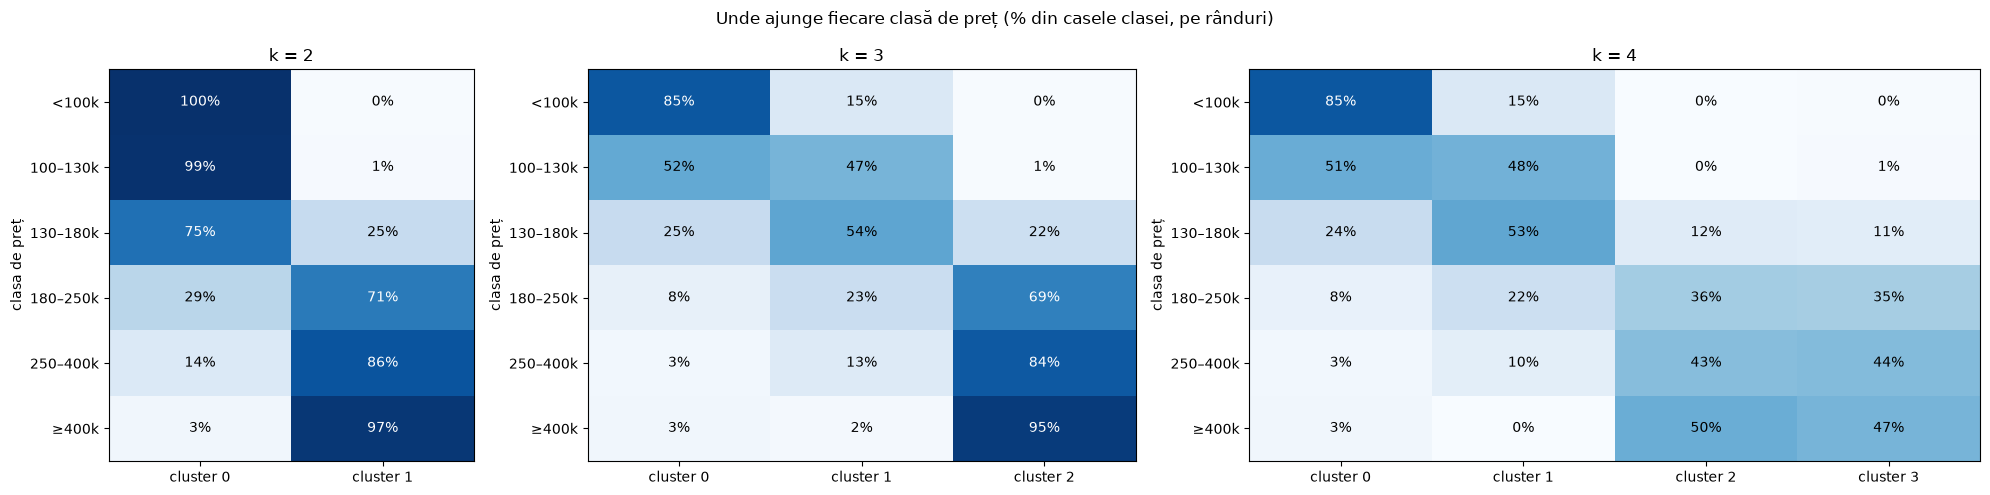

In [42]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

rows = [{"împărțire": f"k-means, k = {k}", "ARI vs clase de preț": adjusted_rand_score(yy, labels[k]),
         "NMI vs clase de preț": normalized_mutual_info_score(yy, labels[k]),
         "silhouette (în Z)": silhouette_score(Z, labels[k])} for k in [2, 3, 4]]
k6 = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit_predict(Z)
rows.append({"împărțire": "k-means, k = 6", "ARI vs clase de preț": adjusted_rand_score(yy, k6),
             "NMI vs clase de preț": normalized_mutual_info_score(yy, k6), "silhouette (în Z)": silhouette_score(Z, k6)})
rows.append({"împărțire": "cele 6 clase de preț", "ARI vs clase de preț": 1.0, "NMI vs clase de preț": 1.0,
             "silhouette (în Z)": silhouette_score(Z, yy)})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [2, 3, 4]})
for ax, k in zip(axes, [2, 3, 4]):
    ct = pd.crosstab(yy, labels[k], normalize="index") * 100        # % din fiecare clasă de preț, pe cluster
    ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(k)); ax.set_xticklabels([f"cluster {c}" for c in range(k)])
    ax.set_yticks(range(6)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(6):
        for j in range(k):
            ax.text(j, i, f"{ct.values[i, j]:.0f}%", ha="center", va="center", color="white" if ct.values[i, j] > 55 else "black")
    ax.set_title(f"k = {k}"); ax.set_ylabel("clasa de preț")
fig.suptitle("Unde ajunge fiecare clasă de preț (% din casele clasei, pe rânduri)")
plt.tight_layout(); plt.show()

## cat din informatia despre pret ramane in componente

,XGBoost,regresie logistică
date de intrare,,
250 features,0.733,0.649
123 componente (98%),0.593,0.648
primele 10 PC,0.542,0.510
primele 3 PC,0.476,0.371
doar PC1,0.341,0.313


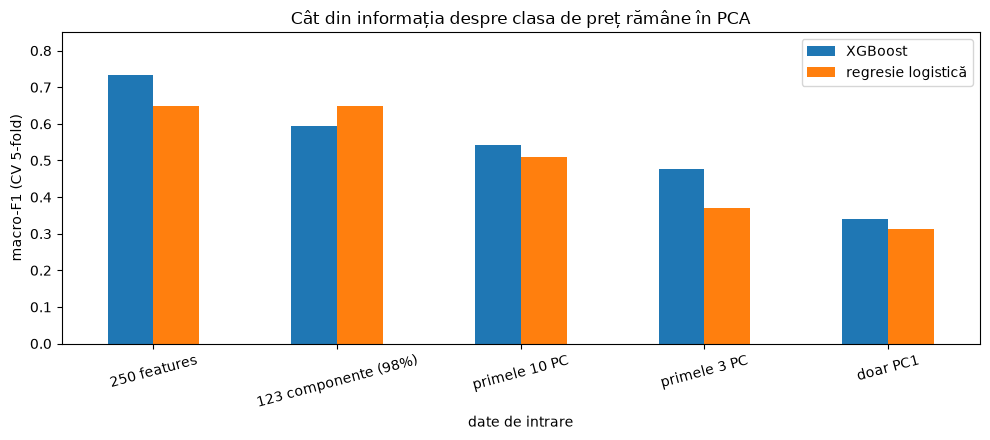

In [43]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from lab3_utils import cv_macro_f1, balanced_weights

Zdf = pd.DataFrame(Z, index=X.index)
Xs = B["X_scaled"]
seturi = {"250 features": (X, Xs), "123 componente (98%)": (Zdf, Zdf), "primele 10 PC": (Zdf.iloc[:, :10], Zdf.iloc[:, :10]),
          "primele 3 PC": (Zdf.iloc[:, :3], Zdf.iloc[:, :3]), "doar PC1": (Zdf.iloc[:, :1], Zdf.iloc[:, :1])}
rez = []
for nume, (d_xgb, d_lr) in seturi.items():
    s_x = cv_macro_f1(XGBClassifier(random_state=42, n_jobs=4), d_xgb, y)
    s_l = cv_macro_f1(LogisticRegression(max_iter=3000), d_lr, y)
    rez.append({"date de intrare": nume, "XGBoost": s_x.mean(), "regresie logistică": s_l.mean()})
rez = pd.DataFrame(rez).set_index("date de intrare")
display(rez.round(3))
rez.plot(kind="bar", figsize=(10, 4.5), rot=15, ylim=(0, 0.85))
plt.ylabel("macro-F1 (CV 5-fold)"); plt.title("Cât din informația despre clasa de preț rămâne în PCA")
plt.tight_layout(); plt.show()

## feature importance si compozitia componentelor

,importanță XGBoost,R² în PC1–3,R² în 123 PC
Overall Qual,0.086,0.515,0.881
Garage Cars,0.050,0.392,0.948
Full Bath,0.025,0.365,0.870
Gr Liv Area,0.020,0.352,0.936
Year Built,0.019,0.748,0.958
Bsmt Qual,0.019,0.443,0.963
Land Contour_HLS,0.018,0.010,1.000
Total Bsmt SF,0.017,0.383,0.874
Neighborhood_NoRidge,0.017,0.078,0.991
MS SubClass_60,0.015,0.664,0.997



Coloane binare (one-hot): 195 din 250, ele conțin 83.6% din varianța totală (după min-max)
Features din top-15 loadings ale PC1–3: 28, importanța lor totală în XGBoost: 0.156 (top-15 după importanță: 0.356; în ambele liste: 3 features)


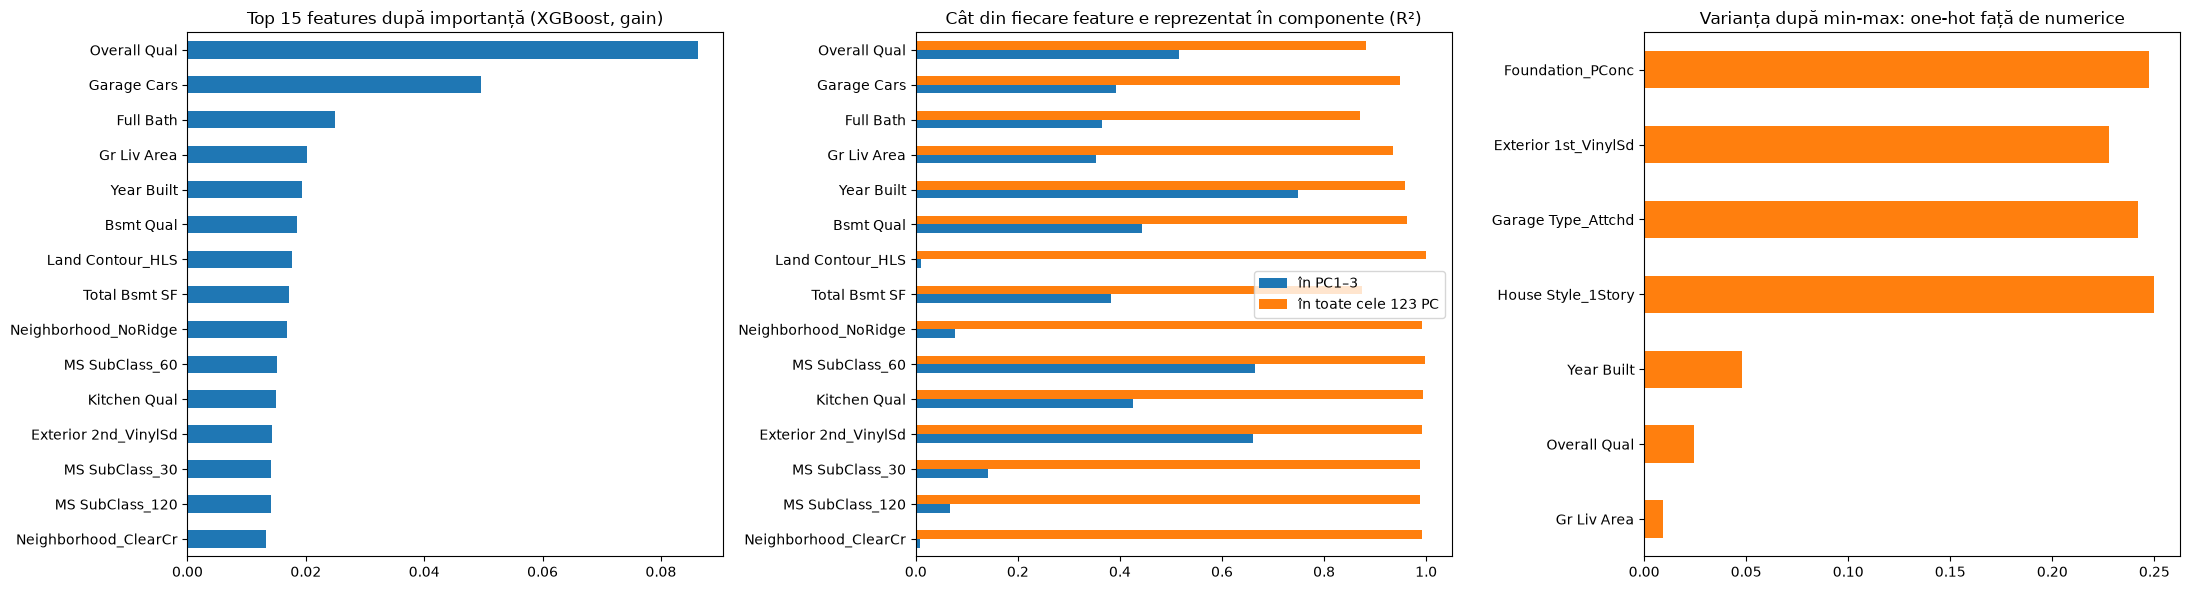

In [44]:
xgb = XGBClassifier(random_state=42, n_jobs=4).fit(X, y, sample_weight=balanced_weights(y))
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
top = imp.head(15).index

C = np.corrcoef(np.c_[Xs.values, Z].T)[:Xs.shape[1], Xs.shape[1]:]          # corelația fiecărui feature cu fiecare PC
R2_3 = pd.Series((C[:, :3] ** 2).sum(1), index=Xs.columns)                  # cât din feature e reprezentat în PC1–3
R2_all = pd.Series((C ** 2).sum(1), index=Xs.columns)                       # ... în toate cele 123 de componente
display(pd.DataFrame({"importanță XGBoost": imp[top], "R² în PC1–3": R2_3[top], "R² în 123 PC": R2_all[top]}).round(3))

binare = [c for c in Xs.columns if Xs[c].nunique() <= 2]
var = Xs.var()
print(f"\nColoane binare (one-hot): {len(binare)} din {Xs.shape[1]}, ele conțin {var[binare].sum() / var.sum():.1%} din varianța totală (după min-max)")

L = pd.DataFrame(B["pca"].components_.T * np.sqrt(B["pca"].explained_variance_), index=X.columns)
top_load = set().union(*[set(L[i].abs().sort_values(ascending=False).index[:15]) for i in range(3)])
print(f"Features din top-15 loadings ale PC1–3: {len(top_load)}, importanța lor totală în XGBoost: {imp[list(top_load)].sum():.3f}"
      f" (top-15 după importanță: {imp.head(15).sum():.3f}; în ambele liste: {len(set(top) & top_load)} features)")

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
imp.head(15)[::-1].plot(kind="barh", ax=axes[0], color="#1f77b4"); axes[0].set_title("Top 15 features după importanță (XGBoost, gain)")
pd.DataFrame({"în PC1–3": R2_3[top], "în toate cele 123 PC": R2_all[top]})[::-1].plot(kind="barh", ax=axes[1])
axes[1].set_title("Cât din fiecare feature e reprezentat în componente (R²)"); axes[1].set_xlim(0, 1.05)
alese = ["Foundation_PConc", "Exterior 1st_VinylSd", "Garage Type_Attchd", "House Style_1Story", "Year Built", "Overall Qual", "Gr Liv Area"]
var[alese][::-1].plot(kind="barh", ax=axes[2], color="#ff7f0e"); axes[2].set_title("Varianța după min-max: one-hot față de numerice")
plt.tight_layout(); plt.show()

**Ce observ**

- **Pe PC1 clasele de preț sunt ordonate, pe PC2 și PC3 sunt amestecate.** Media clasei crește constant pe PC1 (−1,38 la <100k, 1,69 la ≥400k), dar rămâne între −0,42 și 0,41 pe PC2 și PC3. Se potrivește cu corelațiile: PC1 are corelația 0,75 cu clasa de preț, PC2 și PC3 doar 0,04 și −0,11.
- **Clasele de preț nu sunt grupuri separate în spațiul PCA.** Silhouette-ul împărțirii pe clase de preț este −0,006, față de 0,103 pentru k-means cu k = 2.

**Clusterele față de clasele de preț**

- Nu coincid: ARI e 0,15 (k = 2), 0,16 (k = 3), 0,14 (k = 4) și 0,11 chiar și cu k = 6.
- Totuși k = 2 respectă ordinea prețurilor: 100% din casele <100k și 99% din cele 100–130k sunt în clusterul 0, iar 97% din cele ≥400k sunt în clusterul 1. Clusterele despart „mai ieftine" de „mai scumpe", cu amestec la mijloc (75% / 25% pentru 130–180k).
- La k = 4, clasele 250–400k și ≥400k se împart aproape egal între clusterele 2 și 3 (43% / 44%, respectiv 50% / 47%). Despărțirea 1 etaj / 2 etaje nu are legătură cu prețul.

**De ce nu coincid**

1. **Compoziția componentelor.** 195 din cele 250 de coloane sunt one-hot și conțin 83,6% din varianța totală după min-max. De exemplu `Foundation_PConc` are varianța 0,247, iar `Gr Liv Area` 0,0091 și `Overall Qual` 0,0246. PCA caută direcțiile cu varianță mare, nu pe cele relevante pentru preț, deci PC1–PC3 sunt făcute din fundație, exterior, tip de garaj și stil. PC1 are totuși legătură cu prețul, pentru că epoca și calitatea construcției influențează prețul.
2. **Feature importance.** `Overall Qual` (0,086), `Garage Cars` (0,050), `Full Bath`, `Gr Liv Area` și `Year Built` contează cel mai mult pentru preț, dar doar 3 dintre primele 15 features după importanță se află printre cele 28 de features cu loadings mari pe PC1–3. Din `Gr Liv Area` e reprezentat în PC1–3 doar 35%, iar din `Neighborhood_NoRidge` 8%.
3. **Informația despre preț e răspândită în multe componente.** La regresia logistică, 123 de componente păstrează tot ce au cele 250 de features (macro-F1 0,648 față de 0,650), dar primele 10 dau 0,510, primele 3 dau 0,371 și PC1 singur 0,313. Deci prețul nu e concentrat în direcțiile cu cea mai mare varianță.

**Concluzie:** k-means descrie structura dominantă a datelor (epoca și stilul casei), nu prețul. Pentru a prezice clasa de preț trebuie o metodă supervizată (de exemplu XGBoost, cum am făcut în Lab 2), care ajunge la 0,733 pe cele 250 de features față de 0,341 pe PC1.